# 132 · error types: decres-rescale-v1 vs t4-nowmask-v1 vs s9-t2-ref-vase-1k (nb126's error breakdown)
"iou can be misleading": the same three runs, scored by nb126's error classes (binarized at the iou08 threshold) plus prediction style (area, soft pixels, boundary) and multi-object recall.

| label | run | what | eval |
|---|---|---|---|
| **decres-rescale-v1@300** (NEW) | transformer4 `--decoder res --latent-norm rescale`, 300 ep | new best on pooled iou08 | its own ep300 eval, eager (trained with compile 0 on 2026-11-05) |
| **t4-nowmask-v1@300** (BASE) | transformer4 defaults (decoder two, latent ln), 300 ep | baseline | `t4-nowmask-v1-reeval`: ep300 weights re-evaluated eager (ep0000). The checkpoint loads strictly in the current code: 216/216 keys, no missing / unexpected (`w_mask: 0` only switched a loss term off; it never had parameters) |
| **s9-t2-ref-vase-1k@1000** (REF) | transformer2 defaults (`readout ref`, d 128, cls 0), 1000 ep | older reference | trained with `--compile 1`, so its saved evals carry the compile-eval bias: re-evaluated here eager from the ep1000 checkpoint as `s9-t2-ref-vase-1k-reeval` (147/147 keys strict; same 3032 train positions as the other two) |

All three see the same eval samples, so every comparison below is paired.

The error classes follow nb126, but on the **binary** prediction: b = p > THR = 0.08 (utils.THR, the iou08 threshold), never the soft p. Each true object `T_k` is a connected component of truth > 0.5. Every pixel goes to its nearest true object (Voronoi cell `V_k`). `A_k` = |T_k|, `c_k` = centroid of T_k, `D` = √(64²+64²). For a found object, its **main component** is the connected component of b ∩ V_k that overlaps T_k most, or the largest one if none overlaps.

| error | per-object score | range | error if |
|---|---|---|---|
| Missing object | not found: \|b ∩ V_k\| < MISS_FRAC·A_k (MISS_FRAC = 0.2) and b does not touch T_k | {0,1} | any object missing |
| ↳ No prediction | every object missing | {0,1} | all objects missing |
| ↳ Missed object | some object found, some missing (2+ objects) | {0,1} | 1 ≤ #missing < #objects |
| Wrong location | ‖centroid(main) − c_k‖ / D | [0,1] | > LOC_THR = 0.05 (4.5 px) |
| ↳ mirrored | the centroid is nearer a mirror of `c_k` (flip-x / flip-y / rot180 about the box centre) than `c_k`, with the mirror ≥ LOC_THR·D from `c_k` | {0,1} | reported as % of wrong-location samples |
| Wrong scale | \|a − A_k\| / (a + A_k), a = \|main\|, direction too small / too large | [0,1] | > SCALE_THR = 0.2 |
| Wrong shape | 1 − IoU(T_k, main'), main' = main moved to `c_k` and zoomed to area A_k (soft IoU of the interpolated shift) | [0,1] | > SHAPE_THR = 0.3 |
| Extra blob (per sample) | b pixels outside every main component (strays inside a cell, blobs in the cell of a missing object) / \|b\| | [0,1] | > EXTRA_THR = 0.2 |

Primary class priority: No prediction > Missed object > Wrong location > Wrong scale > Wrong shape > Extra blob > OK. Location / scale / shape are only scored for found objects, and a sample counts as an error if any of its objects is over the threshold. Empty-target samples get Extra blob only. ID / OOD = `EvalSummary.ID` / `.OOD`, pooled per sample. An earlier version scored soft mass (Σp) and needed a haze removal for decres-rescale-v1 (section H); the binary scoring makes that unnecessary.

Added in nb132 (beyond nb130's style numbers): iou at .5 and soft IoU next to iou08, per-box style, per-object coverage for multi-object recall, and paired bootstrap CIs over positions (cluster = (experiment, position_id)).

## Summary (details in the Verdict cell at the end)
- **The pooled gains are real but small.** decres-rescale-v1@300 vs t4-nowmask-v1@300: iou08 ID +.026★ / OOD +.014★, iou50 +.045★ / +.016★, biou +.022★ ID. vs s9-t2-ref-vase-1k@1000 (eager re-eval .695 / .386): +.009★ / +.011★, about 2× the noise.
- **Error classes are now binary (b = p > .08).** The soft-mass classes were distorted by decres's near-zero haze, and stray blobs inside a cell moved the COM. Now only the main component of each cell sets location / scale / shape; strays count as Extra blob.
- **Primary OK does not move.** NEW − BASE: ID −0.7, OOD +0.6, both n.s. NEW − REF: ID −4.7★.
- **The OOD gain trades misses for wrong-size, misplaced blobs.** No prediction OOD: 0.9% vs 4.8% (BASE) and 5.3% (REF), −3.8★. Against that, NEW − BASE on OOD: Wrong scale +3.7★, Extra blob +3.6★, Wrong location +1.6★.
- **Masks are bigger.** Over-painted ID 26% vs 14%. Wrong scale ID 12.7% vs 10.9% (+1.8★) and 7.7% for REF (+5.0★).
- **Multi-object recall is not better.** decres finds all objects in 75% of 2-object samples, vs 82% for t4 and 89% for t2-ref (−13 pp★ vs REF). Missed object ID: 3.0 / 2.2 / 1.4%, and in cardboard 6.6 / 2.8 / 1.9%.
- **Wrong shape (section I)** is now a tie with BASE (ID 7.4 vs 8.3%, OOD 29.4 vs 29.7%). NEW is worse than REF on ID (+5.4★); multi-object scenes give 42% vs 11% for REF. Paper figures are in the last section: notebooks/plots/nb132_error_grid_<run> and nb132_error_grid_shared_<run>.

In [1]:
# (run dir, saved epoch): reeval runs save their single eager eval as ep0000
RUNS = [("decres-rescale-v1", 300), ("t4-nowmask-v1-reeval", 0), ("s9-t2-ref-vase-1k-reeval", 0)]
SHOWN = {("decres-rescale-v1", 300): "decres-rescale-v1@300", ("t4-nowmask-v1-reeval", 0): "t4-nowmask-v1@300", ("s9-t2-ref-vase-1k-reeval", 0): "s9-t2-ref-vase-1k@1000"}
SHOW = "rate"         # "rate" = error rate (% of samples) | "mean" = mean error (Missing object always shows its rate)
MISS_FRAC, LOC_THR, SCALE_THR, SHAPE_THR, EXTRA_THR = 0.2, 0.05, 0.2, 0.3, 0.2
THR = 0.08            # the goal threshold (iou08, biou, area ratio)
HAZE = 0.01          # section H only: size of decres-rescale's sub-.01 background haze (the classes are binary at THR, so it no longer matters)
N_BOOT = 2000         # bootstrap resamples over positions
SCRATCH = "/tmp/claude-1000/-home-ethantu-workspace-good-vibrations/4f4d6cce-0580-4e8f-a7d6-b4086bb83fa1/scratchpad"
CACHE = SCRATCH + "/nb132_cache"

In [2]:
import os, sys, pickle
os.environ["CUDA_VISIBLE_DEVICES"] = ""
from pathlib import Path
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
from scipy import ndimage

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src9"))
from dataset import CATEGORIES
from callbacks import EvalSummary
from score import truth

H = W = 64
D = np.hypot(H, W)
CTR = np.array([(H - 1) / 2, (W - 1) / 2])
MIRRORS = {"flip-x": np.array([1, -1]), "flip-y": np.array([-1, 1]), "rot180": np.array([-1, -1])}  # (row, col) signs about CTR
RR, CC = np.mgrid[:H, :W].astype(np.float64)
METRICS = [("nopred", "No prediction"), ("missed", "Missed object"), ("loc", "Wrong location"), ("scale", "Wrong scale"), ("shape", "Wrong shape"), ("extra", "Extra blob")]
RATE = {"nopred": "nopred", "missed": "missed", "loc": "r_loc", "scale": "r_scale", "shape": "r_shape", "extra": "r_extra"}  # per-sample 0/1 error column

def com(p): m = p.sum(); return np.array([(p * RR).sum() / m, (p * CC).sum() / m])

def soft_iou(a, b): return np.minimum(a, b).sum() / max(np.maximum(a, b).sum(), 1e-12)

def recenter(pk, c_pred, c_true, s):
    """pk moved so c_pred lands on c_true and zoomed by s about it: output o <- input c_pred + (o - c_true)/s"""
    return np.clip(ndimage.affine_transform(pk, np.full(2, 1 / s), offset=c_pred - c_true / s, order=1, cval=0.0), 0, 1)

def score(p, y):
    """p (H,W) probabilities, y (H,W) bool truth -> (sample dict, [object dicts]). Everything on the binary mask b = p > THR (the iou08 threshold).
    Per object k: cell V_k = pixels nearest to T_k. Found = |b ∩ V_k| >= MISS_FRAC·|T_k| or b touches T_k. Its main component = the connected
    component of b ∩ V_k with the largest overlap with T_k, else the largest one. Location / scale / shape use the main component only;
    every other b pixel (strays inside a cell, blobs in a cell whose object is missing) counts toward Extra blob"""
    b = p > THR
    lab, n = ndimage.label(y)
    total = b.sum()
    if n == 0:
        return dict(n_obj=0, missing=np.nan, loc=np.nan, scale=np.nan, shape=np.nan, extra=float(total > 0), mirrored=np.nan,
                    r_loc=np.nan, r_scale=np.nan, r_shape=np.nan, r_extra=float(total > 0)), []
    cell = np.stack([ndimage.distance_transform_edt(lab != k) for k in range(1, n + 1)]).argmin(0)
    main = np.zeros_like(b)
    objs = []
    for k in range(n):
        T, bk = lab == k + 1, b & (cell == k)
        A, m, c = T.sum(), bk.sum(), com(T.astype(np.float64))
        o = dict(obj=k, area=float(A), mass=float(m), missing=float(not (m >= MISS_FRAC * A or (bk & T).any())), loc=np.nan, mirrored=np.nan, mirror=None,
                 scale=np.nan, too_small=np.nan, shape=np.nan)
        if not o["missing"]:
            cl, nc = ndimage.label(bk)
            ov = np.bincount(cl[T], minlength=nc + 1)[1:]                       # overlap of each component with T_k
            j = 1 + (ov.argmax() if ov.max() > 0 else np.bincount(cl.ravel(), minlength=nc + 1)[1:].argmax())
            pk = (cl == j).astype(np.float64); main |= cl == j
            a, cp = pk.sum(), com(pk)
            d_true = np.linalg.norm(cp - c)
            o["loc"] = d_true / D
            mir = {nm: CTR + sg * (c - CTR) for nm, sg in MIRRORS.items()}
            ok = {nm: mc for nm, mc in mir.items() if np.linalg.norm(mc - c) >= LOC_THR * D and np.linalg.norm(cp - mc) < d_true}
            o["mirrored"] = float(o["loc"] > LOC_THR and len(ok) > 0)
            if o["mirrored"]: o["mirror"] = min(ok, key=lambda nm: np.linalg.norm(cp - ok[nm]))
            o["scale"], o["too_small"] = abs(a - A) / (a + A), float(a < A)
            o["shape"] = 1 - soft_iou(T.astype(np.float64), recenter(pk, cp, c, np.sqrt(A / a)))
        objs.append(o)
    extra = (b & ~main).sum() / total if total else 0.0
    seen = [o for o in objs if not o["missing"]]
    mean = lambda k: float(np.mean([o[k] for o in seen])) if seen else np.nan
    anyf = lambda k, thr: float(any(o[k] > thr for o in seen))
    return dict(n_obj=n, missing=float(any(o["missing"] for o in objs)), loc=mean("loc"), scale=mean("scale"), shape=mean("shape"),
                extra=float(extra), mirrored=anyf("mirrored", 0.5), r_loc=anyf("loc", LOC_THR), r_scale=anyf("scale", SCALE_THR),
                r_shape=anyf("shape", SHAPE_THR), r_extra=float(extra > EXTRA_THR)), objs

Failed to load CPU gemm_4bit_forward from kernels-community: No module named 'kernels'. Please make sure you already `pip install kernels` and the kernels >= 0.11.1


In [3]:
CAT = {(b, s): c for b, cs in CATEGORIES.items() for c, ss in cs.items() for s in ss}
BOXES = list(CATEGORIES)
ID_CATS, OOD_CATS = list(EvalSummary.ID), list(EvalSummary.OOD)
OTHER_CATS = [c for c in dict.fromkeys(c for cs in CATEGORIES.values() for c in cs) if c not in ID_CATS + OOD_CATS]  # unseen-position, control, ...
B5 = np.ones((5, 5), bool)

def style(p, y):
    """per-sample prediction style at THR (utils.iou08 / biou / area_ratio definitions) + mass ratio, soft-edge fraction, iou at .5 and soft IoU"""
    A = y.sum()
    if A == 0: return dict(iou08=np.nan, iou50=np.nan, siou=np.nan, biou=np.nan, miss08=np.nan, area08=np.nan, area50=np.nan, mass_ratio=np.nan, soft=np.nan)
    b, b5 = p > THR, p > 0.5
    band = lambda m: m & ~ndimage.binary_erosion(m, B5, border_value=1)   # 2 px inner band (mask - 5x5 erosion)
    bp, bt = band(b), band(y)
    return dict(iou08=(b & y).sum() / max((b | y).sum(), 1), iou50=(b5 & y).sum() / max((b5 | y).sum(), 1), siou=soft_iou(y.astype(np.float64), p.astype(np.float64)),
                biou=(bp & bt).sum() / max((bp | bt).sum(), 1), miss08=float(not (b & y).any()),
                area08=b.sum() / A, area50=b5.sum() / A, mass_ratio=p.sum() / A, soft=((p > THR) & (p < 1 - THR)).sum() / max(b.sum(), 1))

def load(pts, where):
    """score every sample in the saved batches; where(pt, experiment) -> (box, split, category). objects also get cov08 = |p>.08 ∩ T_k| / |T_k|"""
    S, O = [], []
    for pt in pts:
        d = torch.load(pt, weights_only=False, map_location="cpu")
        P, info = d["mask_pred"].float().numpy(), d["info"]
        for i in range(len(P)):
            e = info["experiment"][i]
            key = dict(zip(("box", "split", "category"), where(pt, e)), experiment=e, sample_id=int(info["sample_id"][i]),
                       position_id=int(info["position_id"][i]), speaker=int(info["speaker"][i]))
            y = truth(e, key["sample_id"], key["position_id"], key["speaker"], H, W) > 0.5
            s, objs = score(P[i], y)
            lab, _ = ndimage.label(y)
            for o in objs: T = lab == o["obj"] + 1; o["cov08"] = (T & (P[i] > THR)).sum() / T.sum()
            S.append({**key, **s, **style(P[i], y)}); O += [{**key, **o} for o in objs]
    return pd.DataFrame(S), pd.DataFrame(O)

def compute(run, ep):
    """eval splits + the saved train-set eval (split = category = "train"; box from the experiment)"""
    f = Path(CACHE) / (f"n132_{run}_ep{ep:04d}_m{MISS_FRAC}_l{LOC_THR}_s{SCALE_THR}_h{SHAPE_THR}_e{EXTRA_THR}_t{THR}_bin.pkl")   # _bin: classes on b = p > THR
    if f.exists(): return pickle.load(open(f, "rb"))
    hist = ROOT / "runs" / run / "outputs_history"
    S, O = load(sorted(hist.glob(f"eval/*/*/ep{ep:04d}-ba*.pt")), lambda pt, e: (pt.parent.parent.name, pt.parent.name, CAT.get((pt.parent.parent.name, pt.parent.name))))
    box_of = dict(zip(S.experiment, S.box))
    TS, TO = load(sorted(hist.glob(f"train/ep{ep:04d}-ba*.pt")), lambda pt, e: (box_of[e], "train", "train"))
    k = ["experiment", "sample_id", "position_id", "speaker"]
    dup = TS.duplicated(k)  # a batch file can be saved twice (mid-fit + post-fit train eval): keep each sample once
    TO = TO[TO.set_index(k).index.isin(TS[~dup].set_index(k).index)].drop_duplicates(k + ["obj"])
    out = pd.concat([S, TS[~dup]], ignore_index=True), pd.concat([O, TO], ignore_index=True)
    f.parent.mkdir(parents=True, exist_ok=True); pickle.dump(out, open(f, "wb"))
    return out

def split_missing(S, O):
    """Missing object split by how many objects are missing: nopred = every target object missing (nothing painted near any object);
    missed = some object found and some missing (2+ objects only), from score()'s per-object `missing`"""
    k = ["experiment", "sample_id", "position_id", "speaker", "box", "split"]
    nm = O.groupby(k).missing.sum().rename("n_missing").reset_index()
    S = S.drop(columns=["n_missing"], errors="ignore").merge(nm, on=k, how="left")
    has = S.n_obj > 0
    S["nopred"] = np.where(has, (S.n_missing == S.n_obj).astype(float), np.nan)
    S["missed"] = np.where(has, ((S.n_missing > 0) & (S.n_missing < S.n_obj)).astype(float), np.nan)
    return S

DS, DO, LABELS = {}, {}, []
for run, ep in RUNS:
    lab = SHOWN[(run, ep)]
    LABELS.append(lab)
    DS[lab], DO[lab] = compute(run, ep)
    DS[lab] = split_missing(DS[lab], DO[lab])
    s = DS[lab]
    print(f"{lab}: train {(s.category == 'train').sum()} · ID {s.category.isin(ID_CATS).sum()} · OOD {s.category.isin(OOD_CATS).sum()}"
          f" · other {s.category.isin(OTHER_CATS).sum()} · empty-target {(s.n_obj == 0).sum()} · 2+ objects {(s.n_obj >= 2).sum()}"
          f" · pooled iou08 ID {s[s.category.isin(ID_CATS)].iou08.mean():.3f} OOD {s[s.category.isin(OOD_CATS)].iou08.mean():.3f}")
NEW, BASE, REF = LABELS
LABEL = {l: l for l in LABELS}; RUNS = LABELS   # nb126's cells below index DS / LABEL by these labels
K = ["experiment", "sample_id", "position_id", "speaker", "box", "split"]
assert all(set(map(tuple, DS[r][K].to_numpy())) == set(map(tuple, DS[NEW][K].to_numpy())) for r in RUNS), "runs must share eval samples"

decres-rescale-v1@300: train 11219 · ID 2501 · OOD 1419 · other 752 · empty-target 181 · 2+ objects 1503 · pooled iou08 ID 0.703 OOD 0.397
t4-nowmask-v1@300: train 11219 · ID 2501 · OOD 1419 · other 752 · empty-target 181 · 2+ objects 1503 · pooled iou08 ID 0.677 OOD 0.383
s9-t2-ref-vase-1k@1000: train 11219 · ID 2501 · OOD 1419 · other 752 · empty-target 181 · 2+ objects 1503 · pooled iou08 ID 0.695 OOD 0.386


In [4]:
"""sanity: p = truth scores 0 everywhere, p = 0 is a missing object; shape floor = truth shifted by 0.5 px"""
s0 = DS[NEW]
picks = pd.concat([s0[s0.n_obj == 1].sample(5, random_state=0), s0[s0.n_obj >= 2].head(5)])
for _, r in picks.iterrows():
    y = truth(r.experiment, r.sample_id, r.position_id, r.speaker, H, W) > 0.5
    sp, _ = score(y.astype(np.float32), y)
    assert all(abs(sp[k]) < 1e-6 for k in ("missing", "loc", "scale", "shape", "extra")) and all(sp[c] == 0 for c in ("missing", "r_loc", "r_scale", "r_shape", "r_extra")), sp
    assert score(np.zeros((H, W)), y)[0]["missing"] == 1.0
print(f"perfect / empty prediction checks pass on {len(picks)} samples ({(picks.n_obj >= 2).sum()} with 2+ objects)")

floor = []
for _, r in s0[s0.n_obj > 0].iterrows():
    y = truth(r.experiment, r.sample_id, r.position_id, r.speaker, H, W) > 0.5
    floor += [o["shape"] for o in score(np.clip(ndimage.shift(y.astype(np.float64), (0, 0.5), order=1), 0, 1), y)[1]]
SHAPE_FLOOR = float(np.nanmedian(floor))
print(f"shape floor (truth shifted 0.5 px): median {SHAPE_FLOOR:.3f} · p90 {np.nanpercentile(floor, 90):.3f} over {len(floor)} objects")

perfect / empty prediction checks pass on 10 samples (5 with 2+ objects)


shape floor (truth shifted 0.5 px): median 0.128 · p90 0.157 over 17213 objects


In [5]:
RUN_COLOR = ["#3B6FB6", "#B04A5A", "#7A5FB0", "#2E8F83", "#C29237", "#555555"]
BOX_COLOR = {"gastro": "#3B6FB6", "plastic": "#E07B39", "cardboard": "#7A9E4E"}
TRAIN_COLOR = "#4C8C4A"
plt.rcParams.update({"font.size": 16, "xtick.labelsize": 14, "ytick.labelsize": 14, "axes.titlesize": 19, "axes.labelsize": 16})
# 7 panels: (title, column, kind); kind "rate" = always % of samples, "metric" = follows SHOW
PANELS = [("No prediction", "nopred", "rate"), ("Missed object", "missed", "rate"), ("Wrong location", "loc", "metric"), ("Mirrored (% of wrong-location samples)", "mirrored", "rate"),
          ("Wrong scale", "scale", "metric"), ("Wrong shape", "shape", "metric"), ("Extra blob", "extra", "metric")]

def value(s, k, kind):
    if k == "mirrored": return 100 * s[s.r_loc == 1].mirrored.mean()
    if kind == "rate" or SHOW == "rate": return 100 * s[RATE[k]].mean()
    return s[k].mean()

def grid(title, groups, rot=0):
    """one 2x4 figure (7 panels); groups = [[(tick label, samples DataFrame, color, hatch), ...], ...], a gap between groups"""
    pos, bars = [], []
    for g in groups:
        x0 = (pos[-1] + 1.6) if pos else 0
        for j, b in enumerate(g): pos.append(x0 + j); bars.append(b)
    fig, axes = plt.subplots(2, 4, figsize=(46, 19), constrained_layout=True)
    axes.flat[-1].set_axis_off()
    for ax, (name, k, kind) in zip(axes.flat, PANELS):
        vs = [value(s, k, kind) for _, s, _, _ in bars]
        for p, v, (_, _, color, hatch) in zip(pos, vs, bars):
            ax.bar(p, np.nan_to_num(v), 0.85, color=color, hatch=hatch, edgecolor="#222222", linewidth=0.4)
        rate = kind == "rate" or SHOW == "rate"
        top = 100 if rate else 1.15 * np.nanmax(vs + [1e-9])
        for p, v, (_, s, _, _) in zip(pos, vs, bars):
            if np.isnan(v): continue
            txt = f"{v:.0f}" if rate else f"{v:.3f}"
            if k == "mirrored": txt += f"\nn={int((s.r_loc == 1).sum())}"  # wrong-location samples behind the %
            ax.text(p, v + 0.01 * top, txt, ha="center", va="bottom", fontsize=12)
        ax.set_xticks(pos, [b[0] for b in bars], rotation=rot, ha="right" if rot else "center")
        ax.set_ylim(0, 1.12 * top); ax.set_title(name)
        ax.set_ylabel("error rate (% of samples)" if rate else "mean error (0 = perfect)")
        if k == "shape" and not rate: ax.axhline(SHAPE_FLOOR, color="k", ls=":", lw=1)
    fig.suptitle(title + ("" if SHOW == "rate" else f" · dotted = Wrong shape floor (truth shifted 0.5 px) {SHAPE_FLOOR:.3f}"), fontsize=22)
    plt.show()

def cat(s, c): return s[s.category == c] if isinstance(c, str) else s[s.category.isin(c)]

def mirrored(s): return 100 * s[s.r_loc == 1].mirrored.mean()

def split_groups(s):
    """A1 bars: train | ID all, id, multiple | OOD all, ... | other categories"""
    blues, oranges, greys = plt.cm.Blues(np.linspace(0.65, 0.4, len(ID_CATS))), plt.cm.Oranges(np.linspace(0.7, 0.35, len(OOD_CATS))), plt.cm.Greys(np.linspace(0.55, 0.3, len(OTHER_CATS)))
    return [[("train", cat(s, "train"), TRAIN_COLOR, None)],
            [("ID all", cat(s, ID_CATS), "#123A6B", None)] + [(c, cat(s, c), col, None) for c, col in zip(ID_CATS, blues)],
            [("OOD all", cat(s, OOD_CATS), "#8E1F12", None)] + [(c, cat(s, c), col, None) for c, col in zip(OOD_CATS, oranges)],
            [(c, cat(s, c), col, None) for c, col in zip(OTHER_CATS, greys)]]

## A · per run, in depth

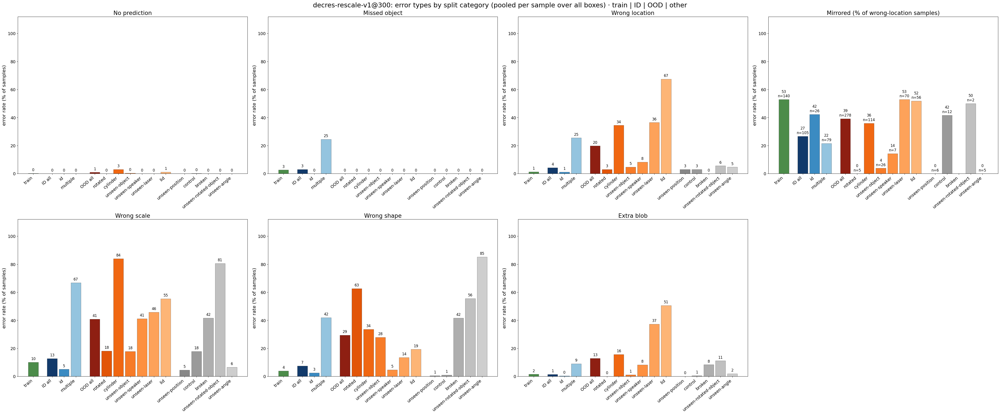

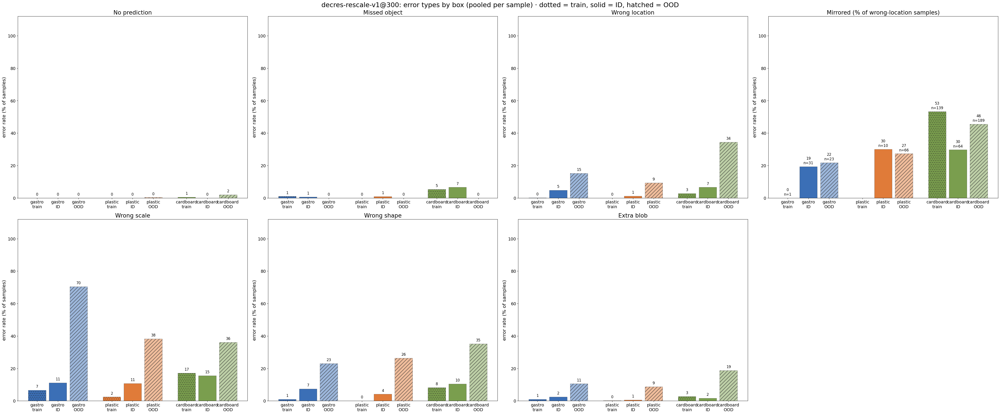

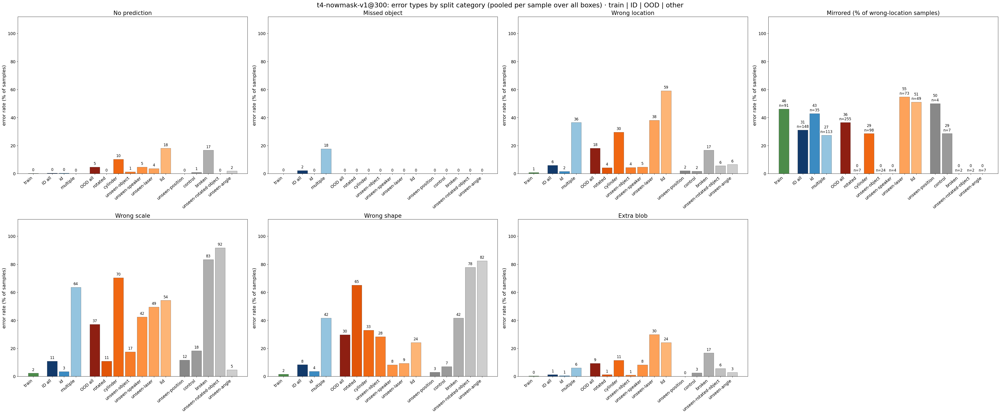

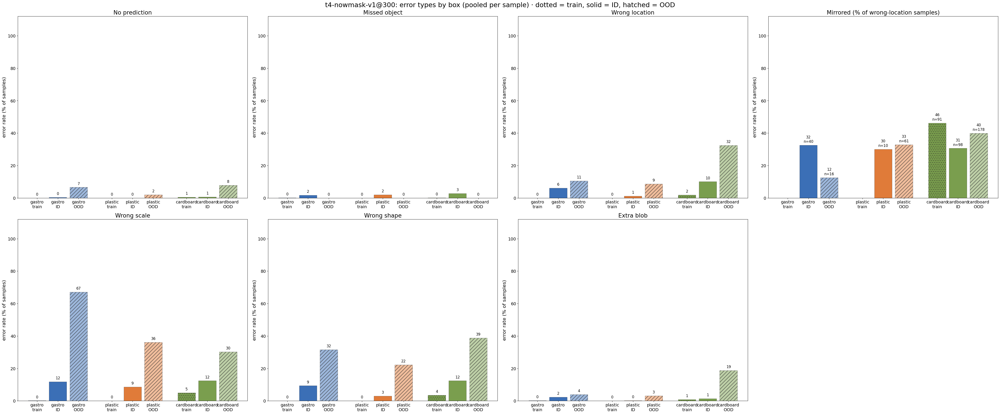

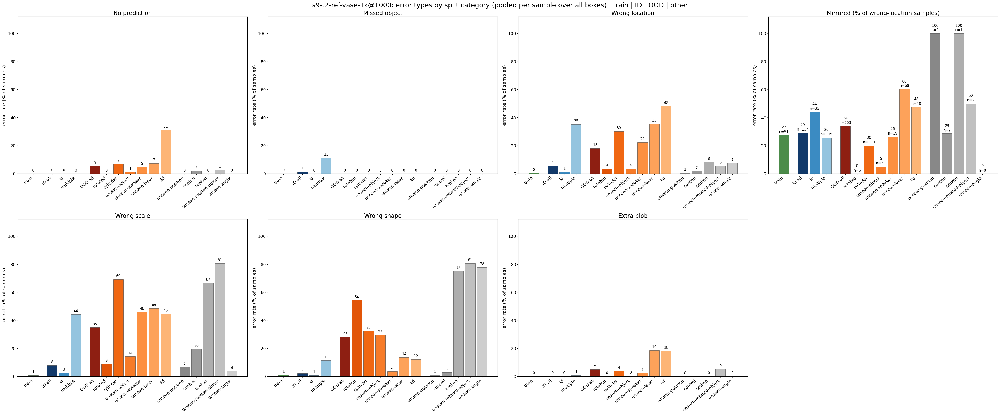

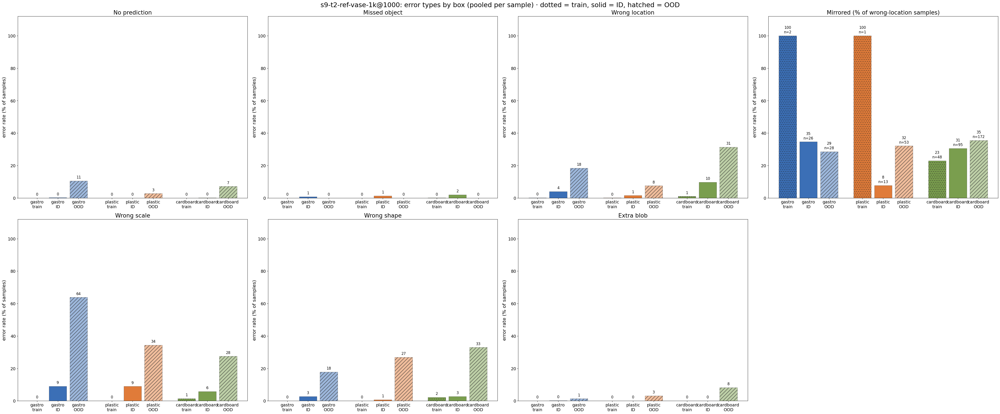

In [6]:
for run in RUNS:
    s = DS[run]
    grid(f"{LABEL[run]}: error types by split category (pooled per sample over all boxes) · train | ID | OOD | other", split_groups(s), rot=40)

    groups = [[(f"{b}\n{g}", cat(s[s.box == b], cs), BOX_COLOR[b] + a, h) for g, cs, a, h in (("train", "train", "FF", ".."), ("ID", ID_CATS, "FF", None), ("OOD", OOD_CATS, "80", "//"))]
              for b in BOXES]
    grid(f"{LABEL[run]}: error types by box (pooled per sample) · dotted = train, solid = ID, hatched = OOD", groups)

Per run: first grid = each category pooled per sample over all boxes (train = the saved train-set eval; other = neither ID nor OOD, e.g. unseen-position); second grid = train / ID / OOD per box. Missing object and Mirrored are always rates.

## A · primary error (exclusive)

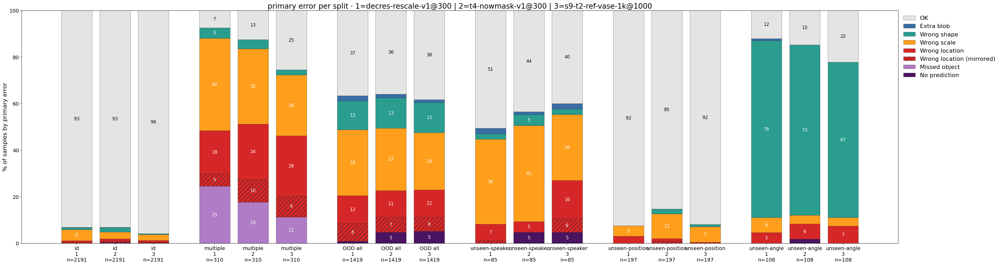

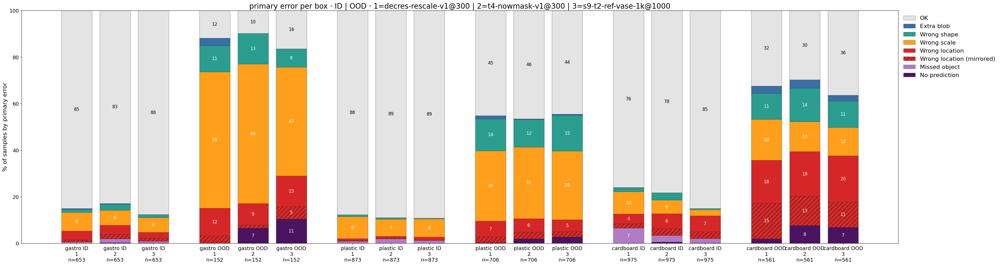

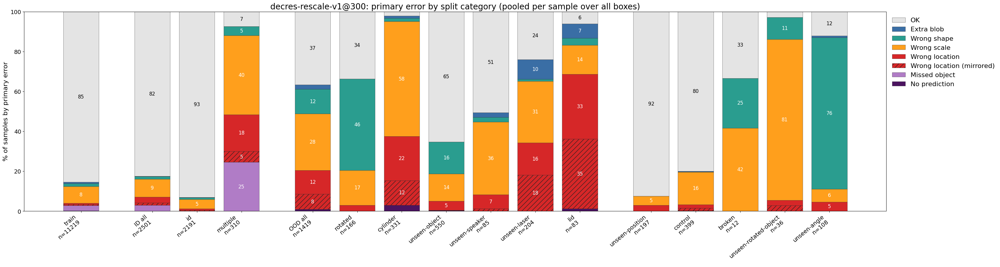

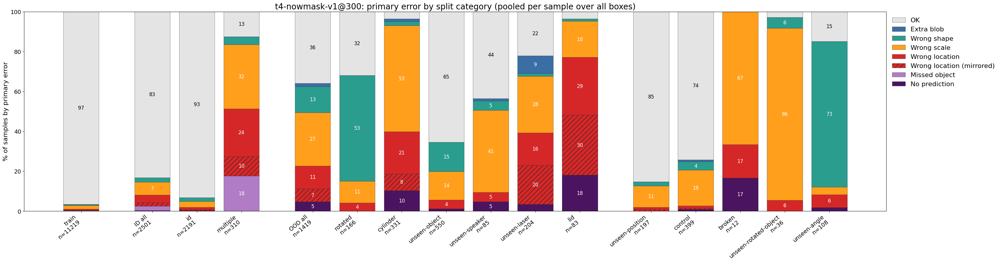

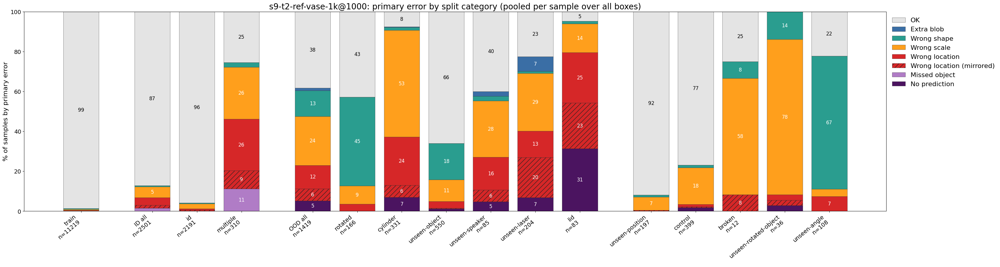

In [7]:
# primary error per sample: first flag in priority order (no prediction > missed object > location > scale > shape > extra > OK); location split into mirrored / not
PRIMARY = [("No prediction", "#4B1460", None), ("Missed object", "#B07CC6", None), ("Wrong location (mirrored)", "#D62728", "//"), ("Wrong location", "#D62728", None),
           ("Wrong scale", "#FF9F1C", None), ("Wrong shape", "#2A9D8F", None), ("Extra blob", "#3A6EA5", None), ("OK", "#E4E4E4", None)]

def primary(s):
    f = lambda c: s[c].fillna(0).to_numpy() > 0
    loc = f("r_loc") & ~f("missing")
    return np.select([f("nopred"), f("missed"), loc & f("mirrored"), loc, f("r_scale"), f("r_shape"), f("r_extra")], range(7), 7)

def stacked(title, bars, figsize, rot=0):
    """bars = [[(label, samples), ...], ...] groups; each bar = 100% of its samples split by primary error"""
    pos, flat = [], []
    for g in bars:
        x0 = (pos[-1] + 1.6) if pos else 0
        for j, b in enumerate(g): pos.append(x0 + j); flat.append(b)
    fig, ax = plt.subplots(figsize=figsize, constrained_layout=True)
    bottom = np.zeros(len(flat))
    shares = np.array([np.bincount(primary(s), minlength=8) / max(len(s), 1) * 100 for _, s in flat])  # (bars, 8)
    for j, (name, color, hatch) in enumerate(PRIMARY):
        ax.bar(pos, shares[:, j], 0.8, bottom=bottom, color=color, hatch=hatch, edgecolor="#222222", linewidth=0.4, label=name)
        for p, b, v in zip(pos, bottom, shares[:, j]):
            if v >= 4: ax.text(p, b + v / 2, f"{v:.0f}", ha="center", va="center", fontsize=12, color="black" if name == "OK" else "white")
        bottom += shares[:, j]
    ax.set_xticks(pos, [f"{l}\nn={len(s)}" for l, s in flat], rotation=rot, ha="right" if rot else "center")
    ax.set_ylim(0, 100); ax.set_ylabel("% of samples by primary error"); ax.set_title(title, fontsize=20)
    h, l = ax.get_legend_handles_labels()
    ax.legend(h[::-1], l[::-1], frameon=False, loc="upper left", bbox_to_anchor=(1.0, 1.0))
    plt.show()

short = lambda r: {NEW: "decres-rescale@300", BASE: "t4-nowmask@300", REF: "t2-ref@1000"}[r]
# the requested split view: id / multiple / OOD (+ unseen-speaker inside it) / unseen-position / unseen-angle, all boxes pooled, one bar per run
SPLITS = [("id", "id"), ("multiple", "multiple"), ("OOD all", OOD_CATS), ("unseen-speaker", "unseen-speaker"), ("unseen-position", "unseen-position"), ("unseen-angle", "unseen-angle")]
stacked("primary error per split · " + " | ".join(f"{i + 1}={r}" for i, r in enumerate(RUNS)),
        [[(f"{g}\n{i + 1}", cat(DS[r], cs)) for i, r in enumerate(RUNS)] for g, cs in SPLITS], (38, 10))
stacked("primary error per box · ID | OOD · " + " | ".join(f"{i + 1}={r}" for i, r in enumerate(RUNS)),
        [[(f"{b} {g}\n{i + 1}", cat(DS[r][DS[r].box == b], cs)) for i, r in enumerate(RUNS)] for b in BOXES for g, cs in (("ID", ID_CATS), ("OOD", OOD_CATS))], (38, 10))
for run in RUNS:
    s = DS[run]
    stacked(f"{LABEL[run]}: primary error by split category (pooled per sample over all boxes)",
            [[(l, d) for l, d, _, _ in g] for g in split_groups(s)], (34, 9), rot=40)

Each sample counted once by its first error in priority order No prediction (every object missing) > Missed object (some found, some missing; 2+ objects) > Wrong location (hatched = mirrored) > Wrong scale > Wrong shape > Extra blob > OK.

## B · runs compared

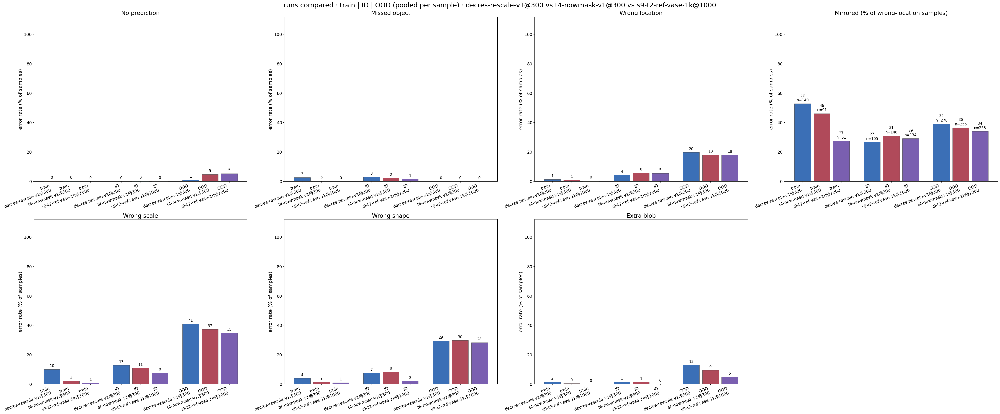

In [8]:
groups = [[(f"{g}\n{LABEL[r]}", cat(DS[r], cs), RUN_COLOR[i % len(RUN_COLOR)], None) for i, r in enumerate(RUNS)]
          for g, cs in (("train", "train"), ("ID", ID_CATS), ("OOD", OOD_CATS))]
grid("runs compared · train | ID | OOD (pooled per sample) · " + " vs ".join(LABEL[r] for r in RUNS), groups, rot=20)

One bar per run inside each of train / ID / OOD.

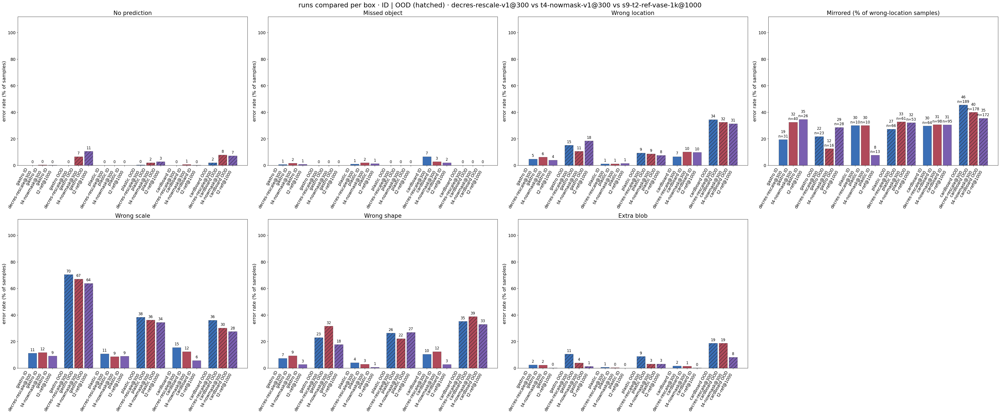

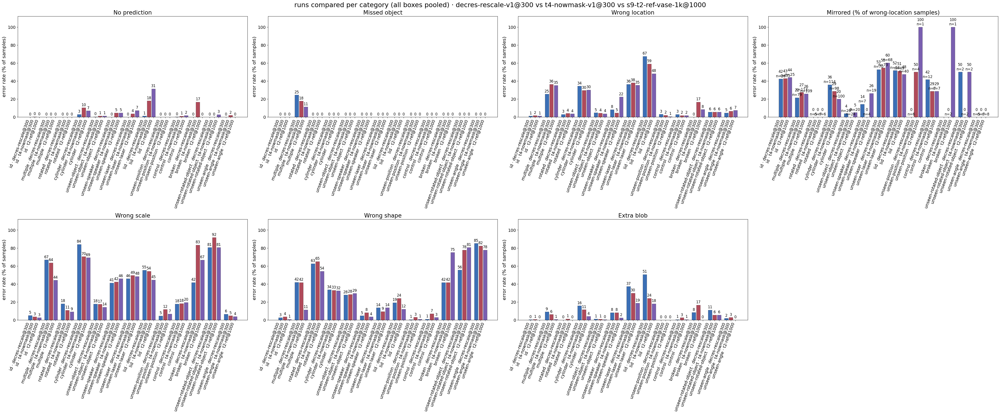

In [9]:
groups = [[(f"{b} {g}\n{short(r)}", cat(DS[r][DS[r].box == b], cs), RUN_COLOR[i], None if g == "ID" else "//") for i, r in enumerate(RUNS)]
          for b in BOXES for g, cs in (("ID", ID_CATS), ("OOD", OOD_CATS))]
grid("runs compared per box · ID | OOD (hatched) · " + " vs ".join(RUNS), groups, rot=60)

groups = [[(f"{c} · {short(r)}", cat(DS[r], c), RUN_COLOR[i], None) for i, r in enumerate(RUNS)] for c in ID_CATS + OOD_CATS + OTHER_CATS]
grid("runs compared per category (all boxes pooled) · " + " vs ".join(RUNS), groups, rot=70)

## C · where the gap is (paired differences, percentage points)
Each row is a sample group; `iou08` = per-sample mean iou08 (pooled), the other columns = run A's error rate minus run B's (pp; **positive = A worse**). Two pairs: decres-rescale − t4-nowmask (the change being tested) and decres-rescale − t2-ref. The paired decomposition below splits the pooled iou08 gap by each sample's primary error under B (rows) and under A (columns).

decres-rescale-v1@300 − t4-nowmask-v1@300


,n,iou08 t4-nowmask@300,iou08 decres-rescale@300,Δ iou08,Δ No prediction pp,Δ Missed object pp,Δ Wrong location pp,Δ Wrong scale pp,Δ Wrong shape pp,Δ Extra blob pp,Δ mirrored pp (of wrong-loc),Δ biou,Δ iou50
group,,,,,,,,,,,,,
train,11219,0.867,0.791,-0.076,-0.009,2.570,0.443,7.765,2.308,1.087,6.703,-0.104,-0.060
ID,2501,0.677,0.703,0.026,-0.320,0.840,-1.719,1.799,-0.880,0.240,-4.414,0.022,0.045
OOD,1419,0.383,0.397,0.014,-3.838,0.000,1.635,3.696,-0.284,3.524,2.738,0.004,0.016
gastro ID,653,0.674,0.717,0.043,-0.306,-1.072,-1.378,-0.613,-1.991,0.153,-13.145,0.040,0.066
gastro OOD,152,0.295,0.303,0.008,-6.579,0.000,4.605,3.289,-8.553,6.579,9.239,0.009,0.012
plastic ID,873,0.737,0.748,0.011,0.000,-1.031,0.000,2.176,1.145,0.344,0.000,0.010,0.028
plastic OOD,706,0.456,0.453,-0.003,-1.700,0.000,0.708,2.125,4.108,5.666,-5.514,-0.007,-0.005
cardboard ID,975,0.627,0.654,0.028,-0.615,3.795,-3.487,3.077,-1.949,0.205,-0.925,0.020,0.046
cardboard OOD,561,0.312,0.350,0.038,-5.829,0.000,2.004,5.829,-3.643,0.000,5.615,0.017,0.045


decres-rescale-v1@300 − s9-t2-ref-vase-1k@1000


,n,iou08 t2-ref@1000,iou08 decres-rescale@300,Δ iou08,Δ No prediction pp,Δ Missed object pp,Δ Wrong location pp,Δ Wrong scale pp,Δ Wrong shape pp,Δ Extra blob pp,Δ mirrored pp (of wrong-loc),Δ biou,Δ iou50
group,,,,,,,,,,,,,
train,11219,0.909,0.791,-0.118,0.235,2.606,0.805,9.394,2.959,1.506,25.406,-0.152,-0.136
ID,2501,0.695,0.703,0.009,-0.080,1.639,-1.160,4.998,5.398,1.399,-2.438,0.012,0.020
OOD,1419,0.386,0.397,0.011,-4.335,0.000,1.777,5.970,1.137,7.963,5.217,0.004,0.014
gastro ID,653,0.694,0.717,0.023,-0.153,-0.153,0.766,2.144,4.594,2.297,-15.261,0.033,0.032
gastro OOD,152,0.275,0.303,0.028,-10.526,0.000,-3.289,6.579,5.263,9.211,-6.832,0.024,0.035
plastic ID,873,0.745,0.748,0.003,0.000,-0.344,-0.344,1.833,3.436,0.573,22.308,0.004,0.012
plastic OOD,706,0.450,0.453,0.003,-2.408,0.000,1.841,3.824,-0.567,5.666,-4.803,0.003,0.001
cardboard ID,975,0.650,0.654,0.004,-0.103,4.615,-3.179,9.744,7.692,1.538,-0.839,0.005,0.018
cardboard OOD,561,0.334,0.350,0.016,-5.100,0.000,3.097,8.561,2.186,10.517,10.038,0.000,0.024


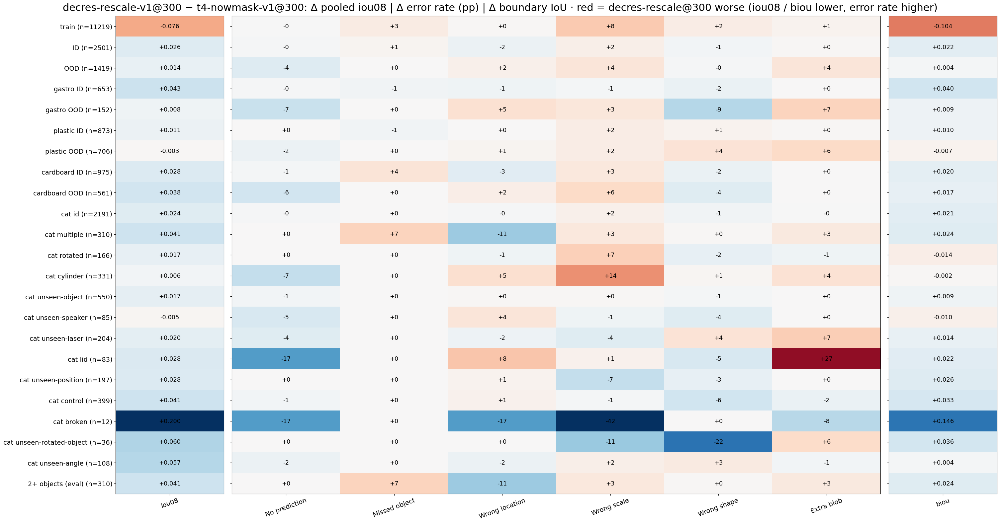

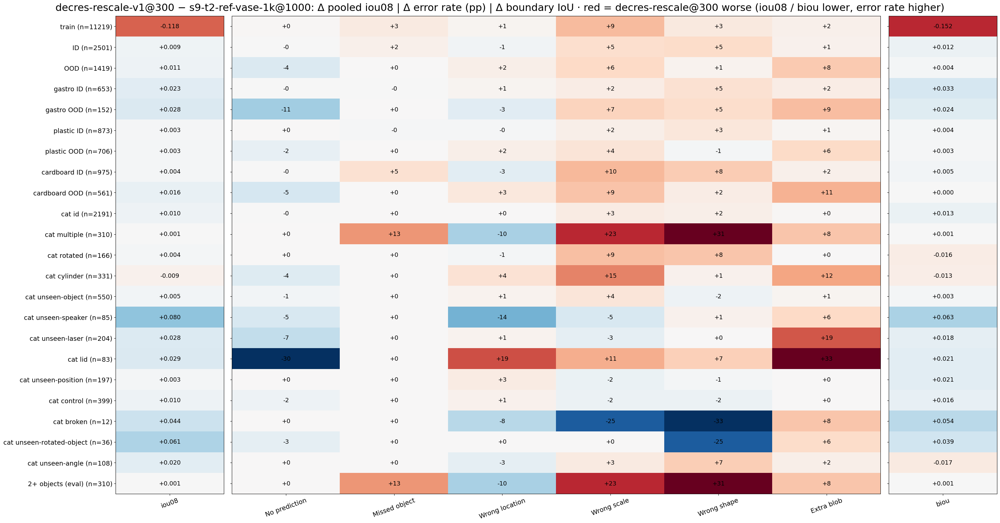

In [10]:
def groups_all():
    yield "train", lambda s: cat(s, "train")
    yield "ID", lambda s: cat(s, ID_CATS)
    yield "OOD", lambda s: cat(s, OOD_CATS)
    for b in BOXES:
        for g, cs in (("ID", ID_CATS), ("OOD", OOD_CATS)): yield f"{b} {g}", (lambda s, b=b, cs=cs: cat(s[s.box == b], cs))
    for c in ID_CATS + OOD_CATS + OTHER_CATS: yield f"cat {c}", (lambda s, c=c: cat(s, c))
    yield "2+ objects (eval)", lambda s: s[(s.n_obj >= 2) & (s.category != "train")]

def gap_table(a, b):
    rows = []
    for g, sel in groups_all():
        sa, sb = sel(DS[a]), sel(DS[b])
        r = {"group": g, "n": len(sa), f"iou08 {short(b)}": sb.iou08.mean(), f"iou08 {short(a)}": sa.iou08.mean(), "Δ iou08": sa.iou08.mean() - sb.iou08.mean()}
        r |= {f"Δ {n} pp": 100 * (sa[RATE[k]].mean() - sb[RATE[k]].mean()) for k, n in METRICS}
        r |= {"Δ mirrored pp (of wrong-loc)": mirrored(sa) - mirrored(sb), "Δ biou": sa.biou.mean() - sb.biou.mean(), "Δ iou50": sa.iou50.mean() - sb.iou50.mean()}
        rows.append(r)
    return pd.DataFrame(rows).set_index("group")

GAP_NB = gap_table(NEW, BASE)
GAP_NR = gap_table(NEW, REF)
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 30); pd.set_option("display.precision", 3)
print(f"{NEW} − {BASE}"); display(GAP_NB.round(3))
print(f"{NEW} − {REF}"); display(GAP_NR.round(3))

def gap_heat(G, title, a):
    cols = ["Δ iou08"] + [f"Δ {n} pp" for _, n in METRICS] + ["Δ biou"]
    M = G[cols].to_numpy(dtype=float)
    fig, axes = plt.subplots(1, 3, figsize=(30, 0.55 * len(G) + 3), gridspec_kw=dict(width_ratios=[1, 6, 1]), constrained_layout=True)
    for ax, sl, vmax, fmt in ((axes[0], [0], 0.2, "{:+.3f}"), (axes[1], list(range(1, 7)), 30, "{:+.0f}"), (axes[2], [7], 0.2, "{:+.3f}")):
        X = M[:, sl]; sgn = 1 if ax is axes[1] else -1          # red = A worse in every panel
        ax.imshow(sgn * X, cmap="RdBu_r", vmin=-vmax, vmax=vmax, aspect="auto")
        for i in range(X.shape[0]):
            for j in range(X.shape[1]):
                if np.isfinite(X[i, j]): ax.text(j, i, fmt.format(X[i, j]), ha="center", va="center", fontsize=13)
        ax.set_xticks(range(len(sl)), [cols[k].replace("Δ ", "").replace(" pp", "") for k in sl], rotation=20)
        ax.set_yticks(range(len(G)), [f"{g} (n={n})" for g, n in zip(G.index, G.n)] if ax is axes[0] else [])
    fig.suptitle(title + f" · red = {short(a)} worse (iou08 / biou lower, error rate higher)", fontsize=22)
    plt.show()

gap_heat(GAP_NB, f"{NEW} − {BASE}: Δ pooled iou08 | Δ error rate (pp) | Δ boundary IoU", NEW)
gap_heat(GAP_NR, f"{NEW} − {REF}: Δ pooled iou08 | Δ error rate (pp) | Δ boundary IoU", NEW)

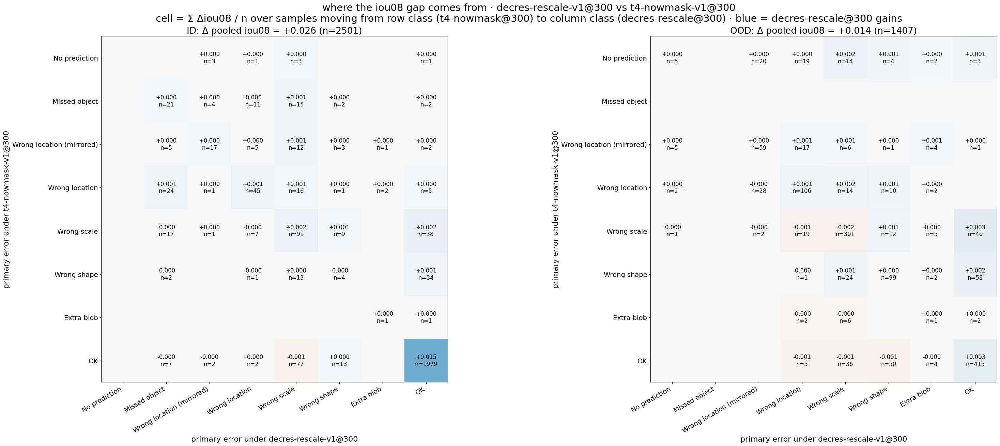

[decres-rescale@300 vs t4-nowmask@300] ID: gap +0.026 · by t4-nowmask@300's primary error (row sums): No prediction +0.001, Missed object +0.001, Wrong location (mirrored) +0.002, Wrong location +0.003, Wrong scale +0.004, Wrong shape +0.001, Extra blob +0.000, OK +0.014
[decres-rescale@300 vs t4-nowmask@300] ID: gap +0.026 · by decres-rescale@300's primary error (column sums): No prediction +0.000, Missed object +0.001, Wrong location (mirrored) +0.000, Wrong location +0.001, Wrong scale +0.003, Wrong shape +0.001, Extra blob +0.000, OK +0.019
[decres-rescale@300 vs t4-nowmask@300] ID: OK→OK cell +0.015 (n=1979) · share by primary error t4-nowmask@300 → decres-rescale@300: No prediction 0→0%, Missed object 2→3%, Wrong location (mirrored) 2→1%, Wrong location 4→3%, Wrong scale 7→9%, Wrong shape 2→1%, Extra blob 0→0%, OK 83→82%
[decres-rescale@300 vs t4-nowmask@300] OOD: gap +0.014 · by t4-nowmask@300's primary error (row sums): No prediction +0.004, Missed object +0.000, Wrong location

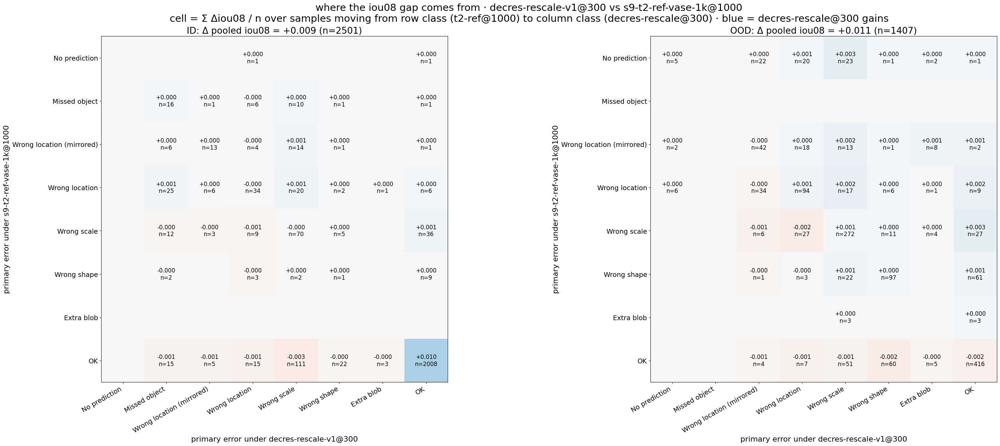

[decres-rescale@300 vs t2-ref@1000] ID: gap +0.009 · by t2-ref@1000's primary error (row sums): No prediction +0.000, Missed object +0.001, Wrong location (mirrored) +0.001, Wrong location +0.003, Wrong scale +0.000, Wrong shape -0.000, Extra blob +0.000, OK +0.004
[decres-rescale@300 vs t2-ref@1000] ID: gap +0.009 · by decres-rescale@300's primary error (column sums): No prediction +0.000, Missed object +0.000, Wrong location (mirrored) -0.001, Wrong location -0.002, Wrong scale -0.000, Wrong shape +0.000, Extra blob -0.000, OK +0.012
[decres-rescale@300 vs t2-ref@1000] ID: OK→OK cell +0.010 (n=2008) · share by primary error t2-ref@1000 → decres-rescale@300: No prediction 0→0%, Missed object 1→3%, Wrong location (mirrored) 2→1%, Wrong location 4→3%, Wrong scale 5→9%, Wrong shape 1→1%, Extra blob 0→0%, OK 87→82%
[decres-rescale@300 vs t2-ref@1000] OOD: gap +0.011 · by t2-ref@1000's primary error (row sums): No prediction +0.004, Missed object +0.000, Wrong location (mirrored) +0.005, W

In [11]:
# paired: same eval samples in both runs; Δ iou08 summed per (primary error under B, under A) cell, / n -> contribution to the pooled gap
NAMES = [n for n, _, _ in PRIMARY]
def paired(a, b, cats):
    sa, sb = cat(DS[a], cats).drop_duplicates(K), cat(DS[b], cats).drop_duplicates(K)
    m = sb.assign(pb=primary(sb)).merge(sa.assign(pa=primary(sa)), on=K, suffixes=("_b", "_a"))
    m = m[m.n_obj_b > 0]
    T = np.zeros((8, 8)); np.add.at(T, (m.pb, m.pa), (m.iou08_a - m.iou08_b) / len(m))
    C = np.zeros((8, 8)); np.add.at(C, (m.pb, m.pa), 1)
    return T, C, len(m), (m.iou08_a - m.iou08_b).mean()

for a, b in ((NEW, BASE), (NEW, REF)):
    fig, axes = plt.subplots(1, 2, figsize=(32, 13), constrained_layout=True)
    for ax, (g, cs) in zip(axes, (("ID", ID_CATS), ("OOD", OOD_CATS))):
        T, C, n, gap = paired(a, b, cs)
        ax.imshow(T, cmap="RdBu", vmin=-0.03, vmax=0.03)
        for i in range(8):
            for j in range(8):
                if C[i, j]: ax.text(j, i, f"{T[i, j]:+.3f}\nn={int(C[i, j])}", ha="center", va="center", fontsize=12)
        ax.set_xticks(range(8), NAMES, rotation=30, ha="right"); ax.set_yticks(range(8), NAMES)
        ax.set_xlabel(f"primary error under {a}"); ax.set_ylabel(f"primary error under {b}")
        ax.set_title(f"{g}: Δ pooled iou08 = {gap:+.3f} (n={n})", fontsize=19)
    fig.suptitle(f"where the iou08 gap comes from · {a} vs {b}\ncell = Σ Δiou08 / n over samples moving from row class ({short(b)}) to column class ({short(a)}) · blue = {short(a)} gains", fontsize=21)
    plt.show()

    for g, cs in (("ID", ID_CATS), ("OOD", OOD_CATS)):
        T, C, n, gap = paired(a, b, cs)
        print(f"[{short(a)} vs {short(b)}] {g}: gap {gap:+.3f} · by {short(b)}'s primary error (row sums): " + ", ".join(f"{NAMES[i]} {T[i].sum():+.3f}" for i in range(8)))
        print(f"[{short(a)} vs {short(b)}] {g}: gap {gap:+.3f} · by {short(a)}'s primary error (column sums): " + ", ".join(f"{NAMES[j]} {T[:, j].sum():+.3f}" for j in range(8)))
        print(f"[{short(a)} vs {short(b)}] {g}: OK→OK cell {T[7, 7]:+.3f} (n={int(C[7, 7])}) · share by primary error {short(b)} → {short(a)}: " + ", ".join(f"{NAMES[j]} {100 * C[j].sum() / n:.0f}→{100 * C[:, j].sum() / n:.0f}%" for j in range(8)))

## C2 · paired differences with bootstrap CIs over positions
Per sample Δ = A − B on the same eval sample. Samples at one position (all its speakers / repeats) are not independent, so the bootstrap resamples **positions** (cluster = (experiment, position_id)) with replacement, N_BOOT times, and recomputes the pooled per-sample mean Δ (ratio of cluster sums). 95% percentile CI. Columns: iou08, iou50, boundary IoU (Δ, higher = A better) and the error / style rates in pp (higher = A has more of it). ★ = CI excludes 0. Per-category rows have only ~10-60 positions: read them as ±.03-.05.

decres-rescale-v1@300 − t4-nowmask-v1@300 (paired, 95% bootstrap CI over positions; ★ = excludes 0)


,n,pos,iou08,iou50,boundary IoU,OK (no error) pp,No prediction pp,Missed object pp,Wrong location pp,Wrong scale pp,Wrong shape pp,Extra blob pp,over-painted (area>1.25) pp,under-painted (area<0.8) pp,soft-pixel fraction pp
group,,,,,,,,,,,,,,,
ID,2501,683,"+0.026 [+0.021,+0.031] ★","+0.045 [+0.040,+0.051] ★","+0.022 [+0.015,+0.028] ★","-0.7 [-2.1,+0.7]","-0.3 [-0.7,-0.0] ★","+0.8 [-0.1,+1.8]","-1.7 [-2.6,-0.8] ★","+1.8 [+0.3,+3.4] ★","-0.9 [-2.3,+0.4]","+0.2 [-0.4,+0.8]","+11.8 [+9.6,+14.2] ★","-5.6 [-7.0,-4.2] ★","+4.5 [+4.0,+4.9] ★"
OOD,1407,426,"+0.014 [+0.007,+0.021] ★","+0.016 [+0.009,+0.023] ★","+0.004 [-0.002,+0.010]","+0.6 [-1.7,+3.0]","-3.8 [-5.1,-2.6] ★","+0.0 [+0.0,+0.0]","+1.6 [+0.1,+3.2] ★","+3.7 [+0.9,+6.4] ★","-0.3 [-3.0,+2.5]","+3.6 [+1.6,+5.6] ★","+12.9 [+10.3,+15.6] ★","-11.3 [-13.8,-9.0] ★","+4.5 [+3.4,+5.6] ★"
gastro ID,653,218,"+0.043 [+0.032,+0.054] ★","+0.066 [+0.054,+0.078] ★","+0.040 [+0.027,+0.052] ★","+2.1 [-0.5,+4.9]","-0.3 [-0.8,+0.0]","-1.1 [-2.1,+0.0]","-1.4 [-3.2,+0.2]","-0.6 [-3.4,+2.1]","-2.0 [-4.8,+0.9]","+0.2 [-1.1,+1.5]","+12.6 [+8.4,+16.8] ★","-8.3 [-11.5,-5.2] ★","+4.0 [+3.1,+4.9] ★"
gastro OOD,152,74,"+0.008 [-0.006,+0.024]","+0.012 [-0.005,+0.030]","+0.009 [-0.005,+0.024]","+2.0 [-2.7,+6.6]","-6.6 [-11.6,-2.4] ★","+0.0 [+0.0,+0.0]","+4.6 [+0.7,+9.0] ★","+3.3 [-4.1,+11.2]","-8.6 [-14.8,-2.7] ★","+6.6 [+0.0,+13.8]","+10.5 [+3.2,+18.3] ★","-9.2 [-15.2,-4.0] ★","+5.4 [+2.2,+9.0] ★"
plastic ID,873,219,"+0.011 [+0.004,+0.019] ★","+0.028 [+0.020,+0.037] ★","+0.010 [-0.001,+0.020]","-1.1 [-3.5,+0.9]","+0.0 [+0.0,+0.0]","-1.0 [-2.0,-0.2] ★","+0.0 [-0.7,+0.7]","+2.2 [-0.2,+4.8]","+1.1 [-0.5,+2.9]","+0.3 [-0.1,+0.9]","+3.6 [+0.7,+6.4] ★","-3.4 [-5.6,-1.6] ★","+6.1 [+5.5,+6.6] ★"
plastic OOD,706,207,"-0.003 [-0.010,+0.004]","-0.005 [-0.013,+0.003]","-0.007 [-0.015,+0.001]","-1.3 [-4.1,+1.7]","-1.7 [-3.0,-0.6] ★","+0.0 [+0.0,+0.0]","+0.7 [-1.1,+2.5]","+2.1 [-0.7,+5.0]","+4.1 [+0.7,+7.2] ★","+5.7 [+3.2,+8.6] ★","+3.8 [+1.4,+6.4] ★","-5.9 [-8.9,-2.9] ★","+6.0 [+4.9,+7.0] ★"
cardboard ID,975,246,"+0.028 [+0.020,+0.036] ★","+0.046 [+0.037,+0.055] ★","+0.020 [+0.010,+0.030] ★","-2.3 [-4.6,+0.0]","-0.6 [-1.6,+0.0]","+3.8 [+1.8,+6.0] ★","-3.5 [-5.3,-1.6] ★","+3.1 [+0.4,+5.6] ★","-1.9 [-4.4,+0.2]","+0.2 [-0.9,+1.4]","+18.8 [+14.5,+23.3] ★","-5.6 [-8.3,-3.2] ★","+3.4 [+2.6,+4.2] ★"
cardboard OOD,549,145,"+0.038 [+0.025,+0.051] ★","+0.045 [+0.032,+0.059] ★","+0.017 [+0.004,+0.028] ★","+2.7 [-1.7,+7.3]","-5.8 [-8.5,-3.4] ★","+0.0 [+0.0,+0.0]","+2.0 [-1.1,+5.0]","+5.8 [+0.2,+11.2] ★","-3.6 [-9.2,+1.6]","+0.0 [-3.4,+3.2]","+25.1 [+19.5,+30.7] ★","-18.8 [-23.4,-14.5] ★","+2.4 [+0.2,+4.8] ★"
cat id,2191,599,"+0.024 [+0.018,+0.029] ★","+0.044 [+0.039,+0.051] ★","+0.021 [+0.015,+0.028] ★","-0.1 [-1.4,+1.2]","-0.4 [-0.8,-0.0] ★","+0.0 [+0.0,+0.0]","-0.4 [-0.9,+0.1]","+1.6 [+0.5,+2.8] ★","-1.0 [-2.1,+0.0]","-0.1 [-0.5,+0.2]","+10.6 [+8.3,+12.9] ★","-2.7 [-3.8,-1.8] ★","+4.4 [+4.0,+4.9] ★"


decres-rescale-v1@300 − s9-t2-ref-vase-1k@1000 (paired, 95% bootstrap CI over positions; ★ = excludes 0)


,n,pos,iou08,iou50,boundary IoU,OK (no error) pp,No prediction pp,Missed object pp,Wrong location pp,Wrong scale pp,Wrong shape pp,Extra blob pp,over-painted (area>1.25) pp,under-painted (area<0.8) pp,soft-pixel fraction pp
group,,,,,,,,,,,,,,,
ID,2501,683,"+0.009 [+0.003,+0.014] ★","+0.020 [+0.014,+0.026] ★","+0.012 [+0.005,+0.019] ★","-4.7 [-6.3,-3.2] ★","-0.1 [-0.2,+0.0]","+1.6 [+0.7,+2.6] ★","-1.2 [-2.2,-0.2] ★","+5.0 [+3.2,+6.7] ★","+5.4 [+4.1,+6.9] ★","+1.4 [+0.8,+2.0] ★","+7.4 [+5.2,+9.7] ★","-0.6 [-1.4,+0.2]","-0.4 [-0.9,+0.1]"
OOD,1407,426,"+0.011 [+0.002,+0.019] ★","+0.014 [+0.005,+0.023] ★","+0.004 [-0.004,+0.012]","-1.7 [-4.2,+0.8]","-4.3 [-6.0,-2.8] ★","+0.0 [+0.0,+0.0]","+1.8 [-0.3,+3.7]","+6.0 [+3.2,+8.8] ★","+1.1 [-1.8,+4.1]","+8.0 [+5.7,+10.4] ★","+9.1 [+6.6,+11.6] ★","-3.1 [-5.8,-0.4] ★","-7.1 [-8.6,-5.6] ★"
gastro ID,653,218,"+0.023 [+0.012,+0.034] ★","+0.032 [+0.020,+0.043] ★","+0.033 [+0.020,+0.046] ★","-2.6 [-5.5,+0.3]","-0.2 [-0.5,+0.0]","-0.2 [-0.9,+0.6]","+0.8 [-0.9,+2.8]","+2.1 [-0.8,+5.1]","+4.6 [+1.7,+7.7] ★","+2.3 [+0.8,+4.1] ★","+4.0 [+0.3,+7.8] ★","-1.4 [-2.8,-0.2] ★","-1.5 [-2.3,-0.7] ★"
gastro OOD,152,74,"+0.028 [+0.005,+0.053] ★","+0.035 [+0.010,+0.063] ★","+0.024 [+0.004,+0.045] ★","-4.6 [-9.7,+0.0]","-10.5 [-18.2,-4.0] ★","+0.0 [+0.0,+0.0]","-3.3 [-10.9,+3.5]","+6.6 [-3.5,+16.4]","+5.3 [-0.7,+11.5]","+9.2 [+2.9,+16.7] ★","+9.9 [+2.1,+19.2] ★","-10.5 [-19.2,-2.8] ★","-1.4 [-7.0,+4.2]"
plastic ID,873,219,"+0.003 [-0.005,+0.011]","+0.012 [+0.004,+0.021] ★","+0.004 [-0.006,+0.015]","-1.4 [-3.5,+0.8]","+0.0 [+0.0,+0.0]","-0.3 [-1.1,+0.5]","-0.3 [-1.5,+0.7]","+1.8 [-0.5,+4.1]","+3.4 [+1.7,+5.4] ★","+0.6 [+0.1,+1.1] ★","-1.3 [-4.2,+1.8]","-1.6 [-3.2,-0.3] ★","-1.4 [-2.0,-0.7] ★"
plastic OOD,706,207,"+0.003 [-0.007,+0.013]","+0.001 [-0.010,+0.012]","+0.003 [-0.007,+0.013]","+0.7 [-2.4,+3.8]","-2.4 [-4.2,-1.0] ★","+0.0 [+0.0,+0.0]","+1.8 [+0.0,+3.6]","+3.8 [+1.0,+6.7] ★","-0.6 [-4.3,+3.2]","+5.7 [+3.1,+8.6] ★","+2.7 [+0.3,+5.2] ★","+5.5 [+2.0,+9.1] ★","-5.6 [-7.1,-4.0] ★"
cardboard ID,975,246,"+0.004 [-0.006,+0.015]","+0.018 [+0.007,+0.029] ★","+0.005 [-0.007,+0.017]","-9.0 [-11.8,-6.3] ★","-0.1 [-0.3,+0.0]","+4.6 [+2.5,+6.9] ★","-3.2 [-5.3,-1.2] ★","+9.7 [+6.5,+13.2] ★","+7.7 [+5.2,+10.3] ★","+1.5 [+0.6,+2.5] ★","+17.4 [+13.3,+21.5] ★","+0.9 [-0.3,+2.3]","+1.2 [+0.3,+2.0] ★"
cardboard OOD,549,145,"+0.016 [+0.001,+0.030] ★","+0.024 [+0.010,+0.039] ★","+0.000 [-0.013,+0.013]","-4.0 [-8.9,+0.9]","-5.1 [-8.2,-2.2] ★","+0.0 [+0.0,+0.0]","+3.1 [-1.1,+7.1]","+8.6 [+3.5,+14.3] ★","+2.2 [-3.4,+7.4]","+10.7 [+6.5,+15.3] ★","+17.1 [+12.2,+22.2] ★","-12.0 [-15.9,-7.9] ★","-10.7 [-13.3,-7.9] ★"
cat id,2191,599,"+0.010 [+0.004,+0.016] ★","+0.021 [+0.015,+0.028] ★","+0.013 [+0.006,+0.021] ★","-2.8 [-4.2,-1.5] ★","-0.1 [-0.2,+0.0]","+0.0 [+0.0,+0.0]","+0.0 [-0.4,+0.5]","+2.5 [+1.4,+3.9] ★","+1.8 [+1.0,+2.8] ★","+0.4 [+0.1,+0.7] ★","+7.1 [+4.8,+9.5] ★","-0.3 [-0.5,-0.0] ★","-0.5 [-0.8,-0.1] ★"


t4-nowmask-v1@300 − s9-t2-ref-vase-1k@1000 (paired, 95% bootstrap CI over positions; ★ = excludes 0)


,n,pos,iou08,iou50,boundary IoU,OK (no error) pp,No prediction pp,Missed object pp,Wrong location pp,Wrong scale pp,Wrong shape pp,Extra blob pp,over-painted (area>1.25) pp,under-painted (area<0.8) pp,soft-pixel fraction pp
group,,,,,,,,,,,,,,,
ID,2501,683,"-0.017 [-0.023,-0.012] ★","-0.025 [-0.031,-0.020] ★","-0.010 [-0.017,-0.003] ★","-4.0 [-5.4,-2.5] ★","+0.2 [-0.0,+0.6]","+0.8 [+0.1,+1.6] ★","+0.6 [-0.4,+1.6]","+3.2 [+1.9,+4.6] ★","+6.3 [+4.9,+7.8] ★","+1.2 [+0.6,+1.7] ★","-4.4 [-6.3,-2.5] ★","+5.0 [+3.8,+6.4] ★","-4.9 [-5.4,-4.4] ★"
OOD,1407,426,"-0.003 [-0.011,+0.004]","-0.002 [-0.010,+0.005]","-0.000 [-0.007,+0.007]","-2.3 [-4.6,+0.0]","-0.5 [-2.0,+1.1]","+0.0 [+0.0,+0.0]","+0.1 [-1.6,+2.0]","+2.3 [-0.1,+4.8]","+1.4 [-1.2,+4.2]","+4.5 [+2.6,+6.5] ★","-3.8 [-5.9,-1.5] ★","+8.2 [+5.4,+11.0] ★","-11.7 [-12.9,-10.4] ★"
gastro ID,653,218,"-0.019 [-0.031,-0.008] ★","-0.034 [-0.046,-0.022] ★","-0.007 [-0.020,+0.007]","-4.7 [-8.1,-1.5] ★","+0.2 [-0.3,+0.8]","+0.9 [+0.3,+1.7] ★","+2.1 [+0.2,+4.4] ★","+2.8 [+0.3,+5.4] ★","+6.6 [+3.7,+9.6] ★","+2.1 [+0.8,+3.8] ★","-8.6 [-12.6,-5.0] ★","+6.9 [+4.1,+10.0] ★","-5.5 [-6.6,-4.3] ★"
gastro OOD,152,74,"+0.020 [-0.003,+0.044]","+0.023 [-0.002,+0.050]","+0.014 [-0.004,+0.034]","-6.6 [-13.8,+0.0]","-3.9 [-9.1,+1.3]","+0.0 [+0.0,+0.0]","-7.9 [-15.1,-1.4] ★","+3.3 [-4.8,+10.3]","+13.8 [+7.2,+21.5] ★","+2.6 [+0.0,+5.9]","-0.7 [-8.5,+6.3]","-1.3 [-7.9,+5.6]","-6.8 [-10.9,-2.5] ★"
plastic ID,873,219,"-0.009 [-0.017,-0.001] ★","-0.016 [-0.024,-0.008] ★","-0.006 [-0.016,+0.005]","-0.2 [-1.9,+1.4]","+0.0 [+0.0,+0.0]","+0.7 [-0.3,+1.9]","-0.3 [-1.5,+0.7]","-0.3 [-1.8,+1.1]","+2.3 [+1.3,+3.5] ★","+0.2 [+0.0,+0.6]","-4.8 [-7.7,-2.1] ★","+1.8 [+0.3,+3.5] ★","-7.4 [-8.1,-6.7] ★"
plastic OOD,706,207,"+0.006 [-0.004,+0.017]","+0.006 [-0.004,+0.017]","+0.010 [-0.000,+0.021]","+2.0 [-1.0,+5.2]","-0.7 [-2.1,+0.4]","+0.0 [+0.0,+0.0]","+1.1 [-0.6,+3.0]","+1.7 [-1.3,+4.6]","-4.7 [-8.2,-1.1] ★","+0.0 [-1.4,+1.3]","-1.1 [-3.4,+1.3]","+11.5 [+7.8,+15.3] ★","-11.6 [-13.0,-10.1] ★"
cardboard ID,975,246,"-0.023 [-0.034,-0.013] ★","-0.028 [-0.039,-0.017] ★","-0.015 [-0.026,-0.003] ★","-6.8 [-9.4,-4.1] ★","+0.5 [-0.1,+1.5]","+0.8 [-0.6,+2.3]","+0.3 [-1.5,+2.3]","+6.7 [+4.1,+9.4] ★","+9.6 [+7.1,+12.4] ★","+1.3 [+0.5,+2.3] ★","-1.3 [-4.4,+1.9]","+6.6 [+4.3,+9.1] ★","-2.3 [-3.1,-1.3] ★"
cardboard OOD,549,145,"-0.022 [-0.034,-0.009] ★","-0.020 [-0.033,-0.008] ★","-0.017 [-0.027,-0.005] ★","-6.7 [-10.7,-3.1] ★","+0.7 [-2.7,+4.0]","+0.0 [+0.0,+0.0]","+1.1 [-2.7,+5.1]","+2.7 [-1.8,+7.4]","+5.8 [+1.1,+10.8] ★","+10.7 [+6.6,+15.1] ★","-8.0 [-12.7,-3.2] ★","+6.7 [+2.0,+11.7] ★","-13.1 [-15.6,-10.7] ★"
cat id,2191,599,"-0.014 [-0.020,-0.008] ★","-0.023 [-0.030,-0.017] ★","-0.008 [-0.015,-0.001] ★","-2.7 [-4.0,-1.5] ★","+0.3 [-0.1,+0.8]","+0.0 [+0.0,+0.0]","+0.5 [-0.1,+1.1]","+0.9 [-0.0,+1.9]","+2.9 [+1.9,+4.0] ★","+0.5 [+0.2,+0.9] ★","-3.6 [-5.5,-1.6] ★","+2.5 [+1.5,+3.4] ★","-4.9 [-5.4,-4.4] ★"


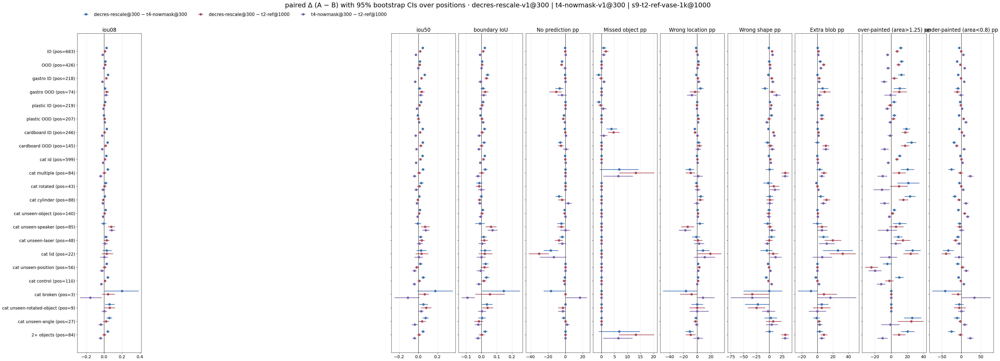

In [12]:
def flags(s):
    """per-sample columns compared in the bootstrap (non-empty targets only)"""
    s = s[s.n_obj > 0]
    return s[K].assign(iou08=s.iou08, iou50=s.iou50, biou=s.biou, nopred=100 * s.nopred, missed=100 * s.missed, loc=100 * s.r_loc, scale=100 * s.r_scale, shape=100 * s.r_shape,
                       extra=100 * s.r_extra, over=100 * (s.area08 > 1.25), under=100 * (s.area08 < 0.8), soft=100 * s.soft, ok=100 * (primary(s) == 7), area08=s.area08)
BOOT_COLS = ["iou08", "iou50", "biou", "ok", "nopred", "missed", "loc", "scale", "shape", "extra", "over", "under", "soft"]
BOOT_NAME = {"iou08": "iou08", "iou50": "iou50", "biou": "boundary IoU", "ok": "OK (no error) pp", "nopred": "No prediction pp", "missed": "Missed object pp", "loc": "Wrong location pp", "scale": "Wrong scale pp",
             "shape": "Wrong shape pp", "extra": "Extra blob pp", "over": "over-painted (area>1.25) pp", "under": "under-painted (area<0.8) pp", "soft": "soft-pixel fraction pp"}
PAIRS = ((NEW, BASE), (NEW, REF), (BASE, REF))

def eval_groups():
    yield "ID", ID_CATS
    yield "OOD", OOD_CATS
    for b in BOXES:
        for g, cs in (("ID", ID_CATS), ("OOD", OOD_CATS)): yield f"{b} {g}", (b, cs)
    for c in ID_CATS + OOD_CATS + OTHER_CATS: yield f"cat {c}", c
    yield "2+ objects", "2+"

def select(s, spec):
    if spec == "2+": return s[(s.n_obj >= 2) & (s.category != "train")]
    if isinstance(spec, tuple): return cat(s[s.box == spec[0]], spec[1])
    return cat(s, spec)

rng = np.random.default_rng(0)
def boot(a, b, spec):
    m = flags(select(DS[a], spec)).merge(flags(select(DS[b], spec)), on=K, suffixes=("_a", "_b"))
    cl = pd.factorize(pd.Series(list(zip(m.experiment, m.position_id))))[0]
    n_cl = cl.max() + 1
    Wt = np.stack([np.bincount(rng.integers(0, n_cl, n_cl), minlength=n_cl) for _ in range(N_BOOT)]).astype(float)   # (N_BOOT, clusters) resample counts
    out = {"n": len(m), "positions": n_cl}
    for c in BOOT_COLS:
        d = (m[f"{c}_a"] - m[f"{c}_b"]).to_numpy(float); ok = np.isfinite(d)
        S, N = np.bincount(cl[ok], d[ok], n_cl), np.bincount(cl[ok], minlength=n_cl).astype(float)
        est = (Wt @ S) / np.maximum(Wt @ N, 1)
        out[c] = (d[ok].mean(), *np.percentile(est, [2.5, 97.5]))
    return out

BOOT_RAW = {p: {g: boot(*p, spec) for g, spec in eval_groups()} for p in PAIRS}

def boot_table(p):
    rows = []
    for g, r in BOOT_RAW[p].items():
        f = lambda c: (f"{r[c][0]:+.3f} [{r[c][1]:+.3f},{r[c][2]:+.3f}]" if c in ("iou08", "iou50", "biou") else f"{r[c][0]:+.1f} [{r[c][1]:+.1f},{r[c][2]:+.1f}]") + (" ★" if r[c][1] > 0 or r[c][2] < 0 else "")
        rows.append({"group": g, "n": r["n"], "pos": r["positions"], **{BOOT_NAME[c]: f(c) for c in BOOT_COLS}})
    return pd.DataFrame(rows).set_index("group")

pd.set_option("display.max_colwidth", 40)
for p in PAIRS:
    print(f"{p[0]} − {p[1]} (paired, 95% bootstrap CI over positions; ★ = excludes 0)"); display(boot_table(p))

# forest plot: Δ iou08 and the class / style rates per group, both pairs vs the baseline / ref
FOREST = ["iou08", "iou50", "biou", "nopred", "missed", "loc", "shape", "extra", "over", "under"]
groups = list(BOOT_RAW[PAIRS[0]])
fig, axes = plt.subplots(1, len(FOREST), figsize=(46, 0.62 * len(groups) + 3), sharey=True, constrained_layout=True)
for ax, c in zip(axes, FOREST):
    for j, (p, col) in enumerate(zip(PAIRS, RUN_COLOR)):
        y = np.arange(len(groups)) + (j - 1) * 0.25
        v = np.array([BOOT_RAW[p][g][c] for g in groups])
        ax.errorbar(v[:, 0], y, xerr=[v[:, 0] - v[:, 1], v[:, 2] - v[:, 0]], fmt="o", ms=7, lw=2, color=col, label=f"{short(p[0])} − {short(p[1])}")
    ax.axvline(0, color="k", lw=1); ax.set_title(BOOT_NAME[c], fontsize=17); ax.grid(axis="x", alpha=0.3)
axes[0].set_yticks(range(len(groups)), [f"{g} (pos={BOOT_RAW[PAIRS[0]][g]['positions']})" for g in groups]); axes[0].invert_yaxis()
axes[0].legend(frameon=False, loc="lower left", bbox_to_anchor=(0, 1.04), fontsize=15, ncol=3)
fig.suptitle(f"paired Δ (A − B) with 95% bootstrap CIs over positions · {NEW} | {BASE} | {REF}", fontsize=22)
plt.show()

## Table

In [13]:
rows = []
for run in RUNS:
    for g, cats in (("train", ["train"]), ("ID", ID_CATS), ("OOD", OOD_CATS)):
        s, o = DS[run][DS[run].category.isin(cats)], DO[run][DO[run].category.isin(cats)]
        sf, mc = o[o.scale > SCALE_THR], o.mirror.value_counts()
        rows.append({"run": LABEL[run], "group": g, "n": len(s),
                     **{f"{n} · error rate %": round(100 * s[RATE[k]].mean(), 1) for k, n in METRICS},
                     **{f"{n} · mean error": round(s[k].mean(), 3) for k, n in METRICS if k not in ("nopred", "missed")},
                     "mirrored (% of wrong-location samples)": round(mirrored(s), 1),
                     "wrong scale: too small %": round(100 * sf.too_small.mean(), 1), "wrong scale: too large %": round(100 * (1 - sf.too_small.mean()), 1),
                     **{f"mirror {m} (objects)": int(mc.get(m, 0)) for m in MIRRORS}})
TABLE = pd.DataFrame(rows).set_index(["run", "group"])
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 30)
TABLE.T

run                                    decres-rescale-v1@300                     t4-nowmask-v1@300                     s9-t2-ref-vase-1k@1000                    
group                                                  train        ID       OOD             train        ID       OOD                  train        ID       OOD
n                                                  11219.000  2501.000  1419.000         11219.000  2501.000  1419.000              11219.000  2501.000  1419.000
No prediction · error rate %                           0.200     0.000     0.900             0.200     0.300     4.800                  0.000     0.100     5.300
Missed object · error rate %                           2.600     3.000     0.000             0.000     2.200     0.000                  0.000     1.400     0.000
Wrong location · error rate %                          1.300     4.200    19.800             0.800     5.900    18.100                  0.500     5.400    18.000
Wrong scale · error rate %                            10.000    12.700    40.900             2.300    10.900    37.200                  0.700     7.700    34.900
Wrong shape · error rate %                             3.900     7.400    29.400             1.600     8.300    29.700                  1.000     2.000    28.300
Extra blob · error rate %                              1.500     1.500    12.900             0.400     1.200     9.400                  0.000     0.100     4.900
Wrong location · mean error                            0.007     0.013     0.051             0.004     0.016     0.048                  0.002     0.015     0.046
Wrong scale · mean error                               0.101     0.104     0.251             0.059     0.086     0.242                  0.047     0.083     0.232
Wrong shape · mean error                               0.149     0.158     0.263             0.130     0.166     0.271                  0.108     0.138     0.264
Extra blob · mean error                                0.011     0.007     0.073             0.003     0.008     0.056                  0.000     0.000     0.034
mirrored (% of wrong-location samples)                52.900    26.700    39.200            46.200    31.100    36.500                 27.500    29.100    34.000
wrong scale: too small %                               5.100    23.700    21.900            15.400    63.700    36.900                  0.000    28.800    27.300
wrong scale: too large %                              94.900    76.300    78.100            84.600    36.300    63.100                100.000    71.200    72.700
mirror flip-x (objects)                               20.000     6.000    32.000             5.000    11.000    25.000                  3.000     6.000    31.000
mirror flip-y (objects)                               25.000    21.000    42.000            19.000    36.000    45.000                  9.000    33.000    43.000
mirror rot180 (objects)                               29.000     1.000    35.000            18.000     1.000    23.000                  2.000     1.000    12.000

In [14]:
# compact: error-class rates (% of samples, a sample can have several) and primary-error shares, per run x box, on ID and OOD (non-empty targets)
rows = []
for b in ["all"] + BOXES:
    for g, cs in (("ID", ID_CATS), ("OOD", OOD_CATS)):
        for r in RUNS:
            s = cat(DS[r] if b == "all" else DS[r][DS[r].box == b], cs); s = s[s.n_obj > 0]
            pr = np.bincount(primary(s), minlength=8) / len(s) * 100
            rows.append({"box": b, "group": g, "run": short(r), "n": len(s), "iou08": s.iou08.mean(), "iou50": s.iou50.mean(), "biou": s.biou.mean(),
                         **{f"{n} %": 100 * s[RATE[k]].mean() for k, n in METRICS}, "OK (primary) %": pr[7],
                         "over %": 100 * (s.area08 > 1.25).mean(), "under %": 100 * (s.area08 < 0.8).mean(), "area08 med": s.area08.median(), "soft %": 100 * s.soft.mean()})
COMPACT = pd.DataFrame(rows).set_index(["box", "group", "run"])
display(COMPACT.round(3))

n  iou08  iou50   biou  No prediction %  Missed object %  Wrong location %  Wrong scale %  Wrong shape %  Extra blob %  OK (primary) %  over %  under %  area08 med  soft %
box       group run                                                                                                                                                                                               
all       ID    decres-rescale@300  2501  0.703  0.721  0.570            0.000            3.039             4.198         12.715          7.437         1.479          82.447  25.790    1.679       1.156  28.947
                t4-nowmask@300      2501  0.677  0.676  0.548            0.320            2.199             5.918         10.916          8.317         1.240          83.167  13.954    7.237       1.084  24.444
                t2-ref@1000         2501  0.695  0.701  0.558            0.080            1.399             5.358          7.717          2.039         0.080          87.125  18.393    2.239       1.128  29.359
          OOD   decres-rescale@300  1407  0.397  0.392  0.284            0.924            0.000            19.758         40.867         29.424        12.154          36.887  47.690   17.697       1.216  35.910
                t4-nowmask@300      1407  0.383  0.376  0.280            4.762            0.000            18.124         37.171         29.709         8.600          36.247  34.826   28.998       1.000  31.375
                t2-ref@1000         1407  0.386  0.378  0.280            5.259            0.000            17.982         34.897         28.287         4.122          38.593  38.593   20.753       1.100  43.028
gastro    ID    decres-rescale@300   653  0.717  0.733  0.612            0.000            0.613             4.747         11.179          7.351         2.450          84.992  24.502    0.613       1.148  28.797
                t4-nowmask@300       653  0.674  0.668  0.572            0.306            1.685             6.126         11.792          9.342         2.297          82.848  11.945    8.882       1.067  24.762
                t2-ref@1000          653  0.694  0.701  0.579            0.153            0.766             3.982          9.035          2.757         0.153          87.596  20.521    1.991       1.132  30.308
          OOD   decres-rescale@300   152  0.303  0.317  0.215            0.000            0.000            15.132         70.395         23.026        10.526          11.842  80.921    3.289       2.587  32.782
                t4-nowmask@300       152  0.295  0.305  0.206            6.579            0.000            10.526         67.105         31.579         3.947           9.868  70.395   12.500       1.950  27.351
                t2-ref@1000          152  0.275  0.282  0.191           10.526            0.000            18.421         63.816         17.763         1.316          16.447  71.053   13.816       2.172  34.164
plastic   ID    decres-rescale@300   873  0.748  0.767  0.615            0.000            0.916             1.145         10.767          4.124         0.573          87.743  17.526    1.604       1.130  25.100
                t4-nowmask@300       873  0.737  0.738  0.605            0.000            1.947             1.145          8.591          2.978         0.229          88.889  13.975    5.040       1.072  19.034
                t2-ref@1000          873  0.745  0.754  0.611            0.000            1.260             1.489          8.935          0.687         0.000          89.118  18.786    3.207       1.114  26.453
          OOD   decres-rescale@300   706  0.453  0.445  0.327            0.283            0.000             9.348         38.244         26.346         8.782          45.184  40.935   21.388       1.052  28.327
                t4-nowmask@300       706  0.456  0.450  0.334            1.983            0.000             8.640         36.119         22.238         3.116          46.459  37.110   27.337       0.974  22.354
                t2-ref@1000   

Too small / too large is over wrong-scale objects; mirror counts are objects (flip-x = column mirrored, flip-y = row mirrored).

## E · prediction style: size, softness, boundary
Per sample with a non-empty target, at THR = 0.08 unless noted: **area ratio** = |p > .08| / |true| (1 = right size), **area50** = same at .5, **mass ratio** = Σp / |true|, **soft fraction** = share of the predicted pixels (p > .08) that are soft (.08 < p < .92), **biou** = boundary IoU of the 2 px inner bands (utils.biou), **iou50** = IoU at p > .5, **soft IoU** = Σmin(p, y) / Σmax(p, y) (threshold-free), **miss08** = no predicted pixel on the truth. Over-painted = area ratio > 1.25, under-painted < 0.8. iou08 rewards over-painting by design (a low threshold on soft masks), so iou50 / soft IoU / biou are the checks that a gain is not just "bigger and blurrier".

n  iou08 (mean)  iou50 (mean)  soft IoU (mean)  boundary IoU (mean)  soft-pixel fraction (mean)  area ratio |p>.08| / |true| (median)  area ratio |p>.5| / |true| (median)  mass ratio Σp / |true| (median)  \
box       group run                                                                                                                                                                                                                                   
all       ID    decres-rescale@300   2501         0.703         0.721            0.684                0.570                       0.289                                 1.156                                1.013                            1.047   
                t4-nowmask@300       2501         0.677         0.676            0.670                0.548                       0.244                                 1.084                                0.974                            0.978   
                t2-ref@1000          2501         0.695         0.701            0.689                0.558                       0.294                                 1.128                                0.978                            0.981   
          OOD   decres-rescale@300   1407         0.397         0.392            0.375                0.284                       0.359                                 1.216                                0.975                            1.065   
                t4-nowmask@300       1407         0.383         0.376            0.374                0.280                       0.314                                 1.000                                0.852                            0.856   
                t2-ref@1000          1407         0.386         0.378            0.372                0.280                       0.430                                 1.100                                0.875                            0.878   
          train decres-rescale@300  11050         0.791         0.839            0.783                0.689                       0.275                                 1.152                                1.014                            1.052   
                t4-nowmask@300      11050         0.867         0.898            0.881                0.793                       0.185                                 1.099                                1.000                            1.006   
                t2-ref@1000         11050         0.909         0.975            0.929                0.840                       0.205                                 1.091                                1.000                            0.995   
cardboard ID    decres-rescale@300    975         0.654         0.672            0.641                0.501                       0.325                                 1.191                                1.025                            1.059   
                t4-nowmask@300        975         0.627         0.626            0.619                0.481                       0.291                                 1.111                                0.975                            0.980   
                t2-ref@1000           975         0.650         0.654            0.643                0.496                       0.313                                 1.138                                0.975                            0.977   
          OOD   decres-rescale@300    549         0.350         0.345            0.329                0.248                       0.465                                 1.222                                0.952                            1.064   
                t4-nowmask@300        549         0.312         0.300            0.298                0.232                       0.441                                 0.950                                0.759                            0.767   
                t2-ref@1000           549         0.334         0.320            0.312  

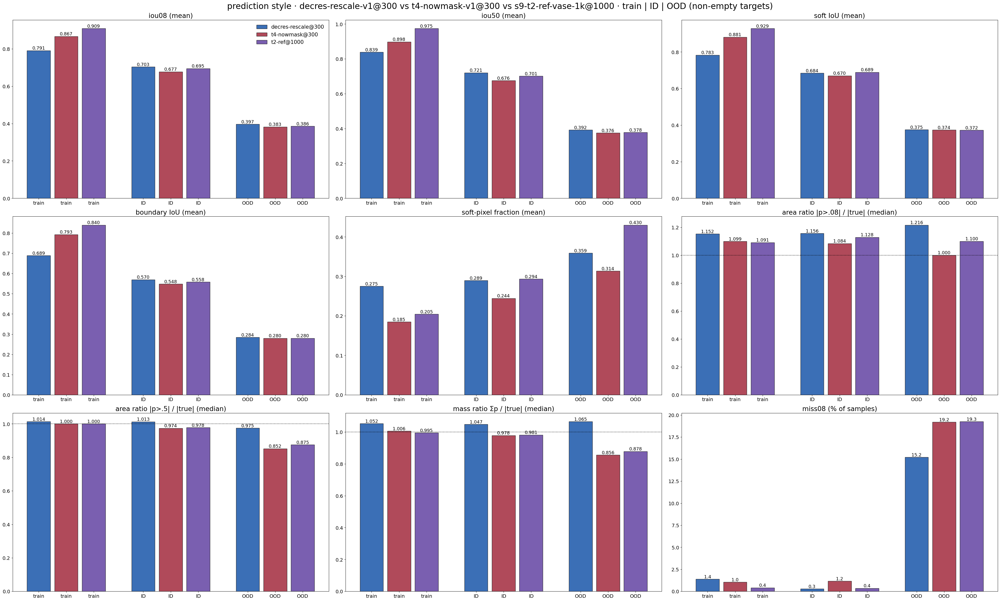

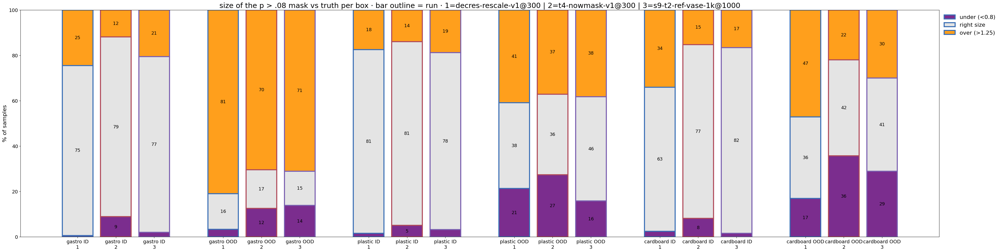

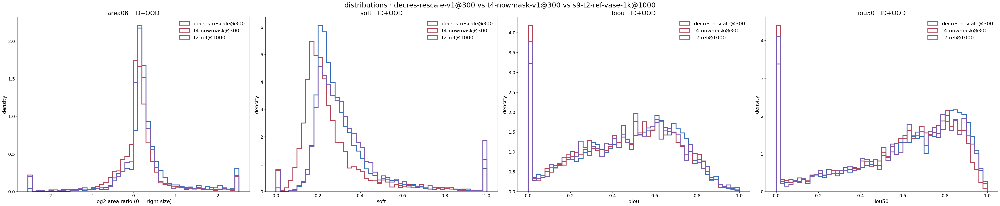

decres-rescale@300 vs t4-nowmask@300: iou08 up >.05 on 1222 samples (71% with a bigger mask, median log2 area ratio +0.13); down >.05 on 703 (76% bigger, median +0.14); corr(Δiou08, Δlog2 area) +0.15; Δiou50 on the iou08-up samples +0.136
decres-rescale@300 vs t2-ref@1000: iou08 up >.05 on 1194 samples (56% with a bigger mask, median log2 area ratio +0.03); down >.05 on 978 (65% bigger, median +0.09); corr(Δiou08, Δlog2 area) +0.08; Δiou50 on the iou08-up samples +0.138


In [15]:
STY = [("iou08", "iou08 (mean)"), ("iou50", "iou50 (mean)"), ("siou", "soft IoU (mean)"), ("biou", "boundary IoU (mean)"), ("soft", "soft-pixel fraction (mean)"),
       ("area08", "area ratio |p>.08| / |true| (median)"), ("area50", "area ratio |p>.5| / |true| (median)"), ("mass_ratio", "mass ratio Σp / |true| (median)"), ("miss08", "miss08 (% of samples)")]
def sty(s, k): return 100 * s[k].mean() if k == "miss08" else s[k].median() if k in ("area08", "area50", "mass_ratio") else s[k].mean()
def style_row(s):
    s = s[s.n_obj > 0]
    return {"n": len(s), **{n: sty(s, k) for k, n in STY}, "area ratio mean": s.area08.mean(),
            "% over-painted (area>1.25)": 100 * (s.area08 > 1.25).mean(), "% under-painted (area<0.8)": 100 * (s.area08 < 0.8).mean(),
            "over / under": (s.area08 > 1.25).mean() / max((s.area08 < 0.8).mean(), 1e-9)}
rows = []
for r in RUNS:
    for g, cs in (("train", "train"), ("ID", ID_CATS), ("OOD", OOD_CATS)):
        rows.append({"run": short(r), "box": "all", "group": g, **style_row(cat(DS[r], cs))})
    for b in BOXES:
        for g, cs in (("ID", ID_CATS), ("OOD", OOD_CATS)):
            rows.append({"run": short(r), "box": b, "group": g, **style_row(cat(DS[r][DS[r].box == b], cs))})
STYLE = pd.DataFrame(rows).set_index(["box", "group", "run"]).sort_index(level=[0, 1], sort_remaining=False); display(STYLE.round(3))

fig, axes = plt.subplots(3, 3, figsize=(40, 24), constrained_layout=True)
for ax, (k, n) in zip(axes.flat, STY):
    pos, xt = 0, []
    for g, cs in (("train", "train"), ("ID", ID_CATS), ("OOD", OOD_CATS)):
        for i, r in enumerate(RUNS):
            s = cat(DS[r], cs); v = sty(s[s.n_obj > 0], k)
            ax.bar(pos, v, 0.85, color=RUN_COLOR[i], edgecolor="#222", label=short(r) if g == "train" else None)
            ax.text(pos, v, f"{v:.3f}" if k != "miss08" else f"{v:.1f}", ha="center", va="bottom", fontsize=13); xt.append((pos, g)); pos += 1
        pos += 0.8
    if k in ("area08", "area50", "mass_ratio"): ax.axhline(1, color="k", ls=":")
    ax.set_xticks(*zip(*xt)); ax.set_title(n)
axes.flat[0].legend(frameon=False, fontsize=15)
fig.suptitle("prediction style · " + " vs ".join(RUNS) + " · train | ID | OOD (non-empty targets)", fontsize=24)
plt.show()

# over vs under per box: stacked share of under (<0.8) / right (0.8-1.25) / over (>1.25) at .08
fig, ax = plt.subplots(figsize=(40, 10), constrained_layout=True)
pos, xt = 0, []
for b in BOXES:
    for g, cs in (("ID", ID_CATS), ("OOD", OOD_CATS)):
        for i, r in enumerate(RUNS):
            s = cat(DS[r][DS[r].box == b], cs); a = s[s.n_obj > 0].area08
            u, o = 100 * (a < 0.8).mean(), 100 * (a > 1.25).mean()
            for bot, h, c, lab in ((0, u, "#7B2D8E", "under (<0.8)"), (u, 100 - u - o, "#E4E4E4", "right size"), (100 - o, o, "#FF9F1C", "over (>1.25)")):
                ax.bar(pos, h, 0.8, bottom=bot, color=c, edgecolor=RUN_COLOR[i], linewidth=3, label=lab if pos == 0 else None)
                if h >= 5: ax.text(pos, bot + h / 2, f"{h:.0f}", ha="center", va="center", fontsize=13)
            xt.append((pos, f"{b} {g}\n{i + 1}")); pos += 1
        pos += 0.8
ax.set_xticks(*zip(*xt)); ax.set_ylim(0, 100); ax.set_ylabel("% of samples"); ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(1, 1))
ax.set_title("size of the p > .08 mask vs truth per box · bar outline = run · " + " | ".join(f"{i + 1}={r}" for i, r in enumerate(RUNS)), fontsize=21)
plt.show()

fig, axes = plt.subplots(1, 4, figsize=(44, 9), constrained_layout=True)
for ax, (k, rng_, lg) in zip(axes, (("area08", (-2.5, 2.5), True), ("soft", (0, 1), False), ("biou", (0, 1), False), ("iou50", (0, 1), False))):
    for i, r in enumerate(RUNS):
        s = cat(DS[r], ID_CATS + OOD_CATS); v = s[s.n_obj > 0][k].dropna().to_numpy()
        v = np.log2(np.clip(v, 2 ** -2.5, 2 ** 2.5)) if lg else v
        ax.hist(v, bins=50, range=rng_, histtype="step", lw=3, color=RUN_COLOR[i], density=True, label=short(r))
    ax.set_xlabel("log2 area ratio (0 = right size)" if lg else k); ax.set_ylabel("density"); ax.legend(frameon=False)
    ax.set_title(f"{k} · ID+OOD")
fig.suptitle("distributions · " + " vs ".join(RUNS), fontsize=22)
plt.show()

# does higher iou08 come with a bigger mask? paired, ID+OOD, samples where |Δ iou08| > .05
for a, b in ((NEW, BASE), (NEW, REF)):
    m = flags(cat(DS[a], ID_CATS + OOD_CATS)).merge(flags(cat(DS[b], ID_CATS + OOD_CATS)), on=K, suffixes=("_a", "_b"))
    m["dla"] = np.log2(m.area08_a.clip(1e-3) / m.area08_b.clip(1e-3))
    m["d"] = m.iou08_a - m.iou08_b
    up, dn = m[m.d > 0.05], m[m.d < -0.05]
    print(f"{short(a)} vs {short(b)}: iou08 up >.05 on {len(up)} samples ({100 * (up.dla > 0).mean():.0f}% with a bigger mask, median log2 area ratio {up.dla.median():+.2f}); "
          f"down >.05 on {len(dn)} ({100 * (dn.dla > 0).mean():.0f}% bigger, median {dn.dla.median():+.2f}); corr(Δiou08, Δlog2 area) {np.corrcoef(m.d, m.dla)[0, 1]:+.2f}; "
          f"Δiou50 on the iou08-up samples {(up.iou50_a - up.iou50_b).mean():+.3f}")

## F · multi-object recall: does it find the second object?
Eval samples with 2+ true objects (two-cubes, cube-vase). Per object: **found (mass)** = not Missing (Σp on its Voronoi cell ≥ 0.2·|T_k|, nb126's rule), **found (.08)** = cov08 = |p > .08 ∩ T_k| / |T_k| ≥ 0.5. Per sample: **all found** = every object found; the **weaker object** = the object with the lower cov08 (usually the second / smaller one). Bootstrap CIs over positions as in C2.

multiple-category samples by number of true components: {2: 310}


samples  object recall (mass) %  object recall (.08) %  all objects found (mass) %  all objects found (.08) %  only 1 found (.08) %  weaker-object cov08 (mean)  stronger-object cov08  iou08  area08 median  Extra blob %
box       run                                                                                                                                                                                                                                           
all       decres-rescale@300      310                  87.742                 60.645                      75.484                     30.323                60.645                       0.309                  0.825  0.392          1.090         9.032
          t4-nowmask@300          310                  91.129                 50.806                      82.258                     24.839                51.935                       0.260                  0.689  0.351          0.906         6.129
          t2-ref@1000             310                  94.355                 63.871                      88.710                     35.161                57.419                       0.339                  0.779  0.391          1.113         0.645
cardboard decres-rescale@300      145                  77.931                 54.828                      55.862                     17.931                73.793                       0.197                  0.830  0.385          1.008         7.586
          t4-nowmask@300          145                  90.690                 46.897                      81.379                     16.552                60.690                       0.193                  0.672  0.332          0.977         4.138
          t2-ref@1000             145                  93.448                 57.241                      86.897                     22.759                68.966                       0.251                  0.777  0.365          1.131         0.690
gastro    decres-rescale@300       69                  97.101                 52.174                      94.203                     26.087                52.174                       0.287                  0.717  0.317          1.270        17.391
          t4-nowmask@300           69                  92.029                 29.710                      84.058                     10.145                39.130                       0.187                  0.549  0.257          0.857        15.942
          t2-ref@1000              69                  96.377                 60.870                      92.754                     34.783                52.174                       0.329                  0.686  0.346          1.065         1.449
plastic   decres-rescale@300       96                  95.833                 75.521                      91.667                     52.083                46.875                       0.493                  0.896  0.455          1.138         5.208
          t4-nowmask@300           96                  91.146                 71.875                      82.292                     47.917                47.917                       0.415                  0.816  0.447          0.853         2.083
          t2-ref@1000              96                  94.271                 76.042                      88.542                     54.167                43.750                       0.480                  0.847  0.461          1.152         0.000

decres-rescale@300 − t4-nowmask@300 on 2+ object samples: all found (.08) +0.055 [-0.006,+0.121] (84 pos) · all found (mass) -0.068 [-0.146,+0.003] (84 pos) · weaker-object cov08 +0.049 [+0.006,+0.094] (84 pos)
decres-rescale@300 − t2-ref@1000 on 2+ object samples: all found (.08) -0.048 [-0.119,+0.026] (84 pos) · all found (mass) -0.132 [-0.204,-0.061] (84 pos) · weaker-object cov08 -0.030 [-0.073,+0.013] (84 pos)
t4-nowmask@300 − t2-ref@1000 on 2+ object samples: all found (.08) -0.103 [-0.167,-0.037] (84 pos) · all found (mass) -0.065 [-0.121,-0.013] (84 pos) · weaker-object cov08 -0.079 [-0.119,-0.039] (84 pos)


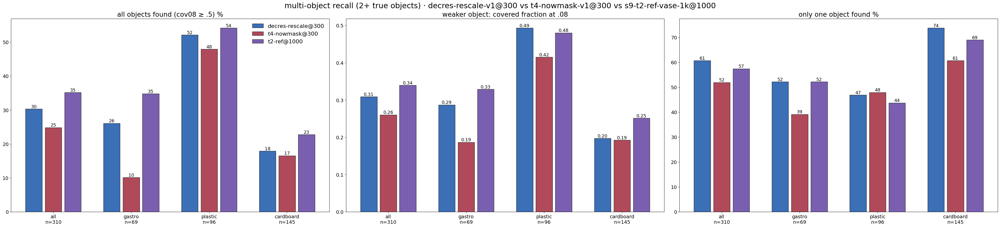

In [16]:
KO = ["experiment", "sample_id", "position_id", "speaker", "box", "split"]
def multi(r):
    o = DO[r][(DO[r].category != "train")]
    o = o.merge(DS[r][KO + ["n_obj"]], on=KO)
    o = o[o.n_obj >= 2].assign(found_mass=lambda x: 1 - x.missing, found08=lambda x: (x.cov08 >= 0.5).astype(float))
    g = o.groupby(KO)
    per = pd.DataFrame({"all_mass": g.found_mass.min(), "all08": g.found08.min(), "weak_cov": g.cov08.min(), "strong_cov": g.cov08.max(), "n_found08": g.found08.sum()}).reset_index()
    return o, per

print("multiple-category samples by number of true components:", cat(DS[NEW], "multiple").n_obj.value_counts().sort_index().to_dict())
rows, PER = [], {}
for r in RUNS:
    o, per = multi(r); PER[r] = per
    s = DS[r]; s2 = s[(s.n_obj >= 2) & (s.category != "train")]
    for b in ["all"] + BOXES:
        ob, pb, sb = (o, per, s2) if b == "all" else (o[o.box == b], per[per.box == b], s2[s2.box == b])
        rows.append({"run": short(r), "box": b, "samples": len(pb), "object recall (mass) %": 100 * ob.found_mass.mean(), "object recall (.08) %": 100 * ob.found08.mean(),
                     "all objects found (mass) %": 100 * pb.all_mass.mean(), "all objects found (.08) %": 100 * pb.all08.mean(),
                     "only 1 found (.08) %": 100 * (pb.n_found08 == 1).mean(), "weaker-object cov08 (mean)": pb.weak_cov.mean(), "stronger-object cov08": pb.strong_cov.mean(),
                     "iou08": sb.iou08.mean(), "area08 median": sb.area08.median(), "Extra blob %": 100 * sb.r_extra.mean()})
MULTI = pd.DataFrame(rows).set_index(["box", "run"]).sort_index(level=0, sort_remaining=False); display(MULTI.round(3))

# paired bootstrap of the multi-object numbers
def boot_multi(a, b, col):
    m = PER[a].merge(PER[b], on=KO, suffixes=("_a", "_b"))
    cl = pd.factorize(pd.Series(list(zip(m.experiment, m.position_id))))[0]; n_cl = cl.max() + 1
    d = (m[f"{col}_a"] - m[f"{col}_b"]).to_numpy(float)
    S, N = np.bincount(cl, d, n_cl), np.bincount(cl, minlength=n_cl).astype(float)
    Wt = np.stack([np.bincount(rng.integers(0, n_cl, n_cl), minlength=n_cl) for _ in range(N_BOOT)]).astype(float)
    return d.mean(), *np.percentile((Wt @ S) / (Wt @ N), [2.5, 97.5]), n_cl
for a, b in PAIRS:
    print(f"{short(a)} − {short(b)} on 2+ object samples: " + " · ".join(
        f"{n} {v:+.3f} [{lo:+.3f},{hi:+.3f}] ({pos} pos)" for n, (v, lo, hi, pos) in
        (("all found (.08)", boot_multi(a, b, "all08")), ("all found (mass)", boot_multi(a, b, "all_mass")), ("weaker-object cov08", boot_multi(a, b, "weak_cov")))))

fig, axes = plt.subplots(1, 3, figsize=(40, 9), constrained_layout=True)
for ax, (col, ttl) in zip(axes, (("all objects found (.08) %", "all objects found (cov08 ≥ .5) %"), ("weaker-object cov08 (mean)", "weaker object: covered fraction at .08"), ("only 1 found (.08) %", "only one object found %"))):
    for j, b in enumerate(["all"] + BOXES):
        for i, r in enumerate(RUNS):
            v = MULTI.loc[(b, short(r)), col]; x = j * (len(RUNS) + 1) + i
            ax.bar(x, v, 0.85, color=RUN_COLOR[i], edgecolor="#222", label=short(r) if j == 0 else None)
            ax.text(x, v, f"{v:.2f}" if "cov" in col else f"{v:.0f}", ha="center", va="bottom", fontsize=13)
    ax.set_xticks([j * (len(RUNS) + 1) + 1 for j in range(4)], [f"{b}\nn={int(MULTI.loc[(b, short(RUNS[0])), 'samples'])}" for b in ["all"] + BOXES]); ax.set_title(ttl)
axes[0].legend(frameon=False)
fig.suptitle("multi-object recall (2+ true objects) · " + " vs ".join(RUNS), fontsize=22)
plt.show()

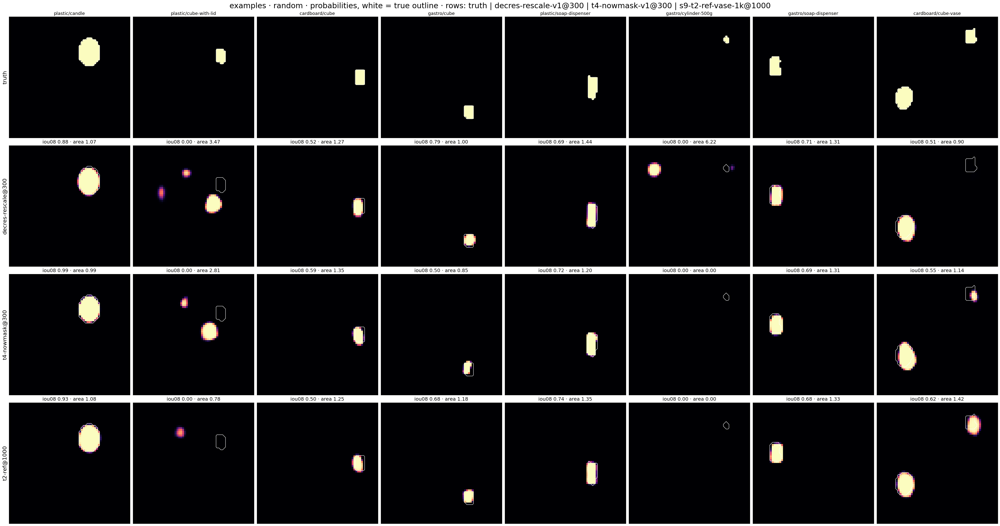

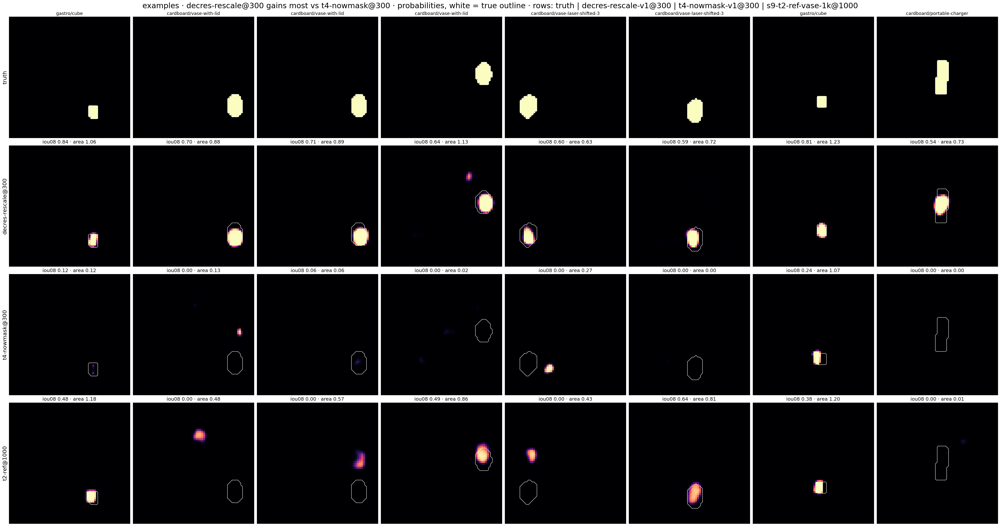

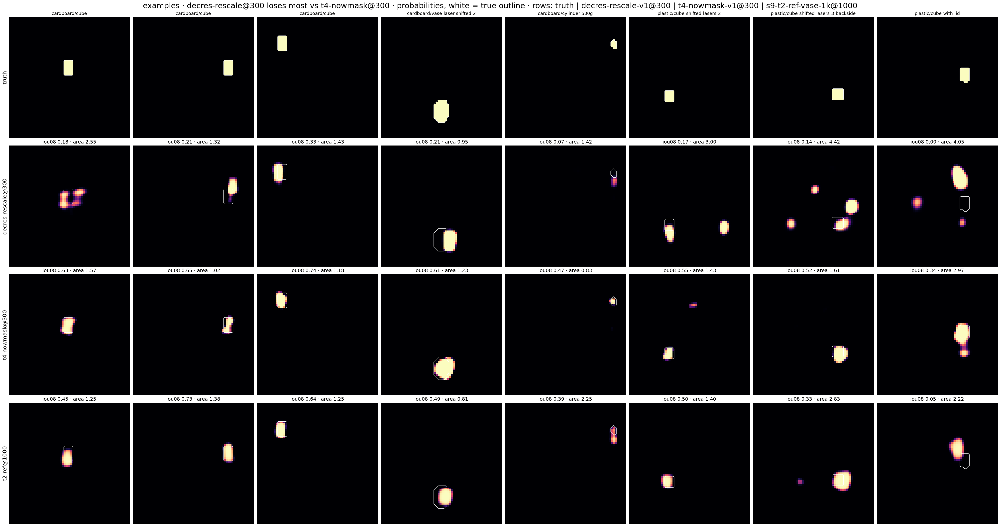

In [17]:
# examples: rows truth | NEW | BASE | REF. 8 random ID+OOD samples (seed 0) + the 8 samples where NEW gains the most iou08 over BASE + the 8 where it loses the most
DIRS = dict(zip(LABELS, [(r, e) for r, e in [("decres-rescale-v1", 300), ("t4-nowmask-v1-reeval", 0), ("s9-t2-ref-vase-1k-reeval", 0)]]))
def pred_of(lab, r):
    run, ep = DIRS[lab]
    for pt in sorted((ROOT / "runs" / run / "outputs_history/eval" / r.box / r.split).glob(f"ep{ep:04d}-ba*.pt")):
        d = torch.load(pt, weights_only=False, map_location="cpu"); info = d["info"]
        for i in range(len(d["mask_pred"])):
            if (info["experiment"][i], int(info["sample_id"][i]), int(info["position_id"][i]), int(info["speaker"][i])) == (r.experiment, r.sample_id, r.position_id, r.speaker):
                return d["mask_pred"][i].float().numpy()
ev = lambda r: cat(DS[r], ID_CATS + OOD_CATS).drop_duplicates(K).set_index(K)
dm = ev(NEW)[["iou08", "area08"]].join(ev(BASE)[["iou08", "area08"]], rsuffix="_b").dropna()
dm["d"] = dm.iou08 - dm.iou08_b
sets = {"random": cat(DS[BASE], ID_CATS + OOD_CATS).drop_duplicates(K).query("n_obj > 0").sample(8, random_state=0),
        f"{short(NEW)} gains most vs {short(BASE)}": dm.nlargest(8, "d").reset_index(), f"{short(NEW)} loses most vs {short(BASE)}": dm.nsmallest(8, "d").reset_index()}
for ttl, pick in sets.items():
    fig, axes = plt.subplots(4, 8, figsize=(40, 21), constrained_layout=True)
    for j, (_, r) in enumerate(pick.iterrows()):
        y = truth(r.experiment, r.sample_id, r.position_id, r.speaker, H, W) > 0.5
        for i, (lab, p) in enumerate([("truth", y.astype(float))] + [(l, pred_of(l, r)) for l in LABELS]):
            ax = axes[i, j]; ax.imshow(p, vmin=0, vmax=1, cmap="magma"); ax.contour(y, [0.5], colors="w", linewidths=1); ax.set_xticks([]); ax.set_yticks([])
            if i: b = p > THR; ax.set_title(f"iou08 {(b & y).sum() / (b | y).sum():.2f} · area {b.sum() / y.sum():.2f}", fontsize=14)
            else: ax.set_title(f"{r.box}/{r.split}", fontsize=13)
            if j == 0: ax.set_ylabel(short(lab) if i else lab, fontsize=16)
    fig.suptitle(f"examples · {ttl} · probabilities, white = true outline · rows: truth | {NEW} | {BASE} | {REF}", fontsize=22)
    plt.show()

## H · why the classes are binary
decres-rescale-v1 never outputs an exact 0. Its probabilities bottom out around 1e-3 to 1e-2 over the whole 64×64 grid, while the other two saturate to 0 in most of the background. nb126's original classes were soft-mass statistics (Σp per Voronoi cell), so that haze leaked into them: it hid misses, raised Wrong shape, pulled the COM and added Extra mass. An earlier version of this notebook zeroed p < .01 and scored twice.

score() now binarizes first (b = p > THR = .08, the iou08 threshold), so the haze cannot reach any class. Everything above and below uses that one thresholded scoring. The cell below only measures the haze.

In [18]:
# haze size per run (eval samples): share of the total mass sitting in p < HAZE pixels
for (run, ep), lab in zip([("decres-rescale-v1", 300), ("t4-nowmask-v1-reeval", 0), ("s9-t2-ref-vase-1k-reeval", 0)], LABELS):
    fr, nz = [], []
    for pt in sorted((ROOT / "runs" / run / "outputs_history/eval").glob(f"*/*/ep{ep:04d}-ba*.pt")):
        P = torch.load(pt, weights_only=False, map_location="cpu")["mask_pred"].float().numpy()
        fr += list((P * (P < HAZE)).sum((1, 2)) / np.maximum(P.sum((1, 2)), 1e-9)); nz += list(((P > 0) & (P < HAZE)).mean((1, 2)))
    print(f"{lab}: mass in p < {HAZE}: mean {100 * np.mean(fr):.1f}% of Σp · pixels with 0 < p < {HAZE}: mean {100 * np.mean(nz):.0f}% of the grid")

decres-rescale-v1@300: mass in p < 0.01: mean 5.2% of Σp · pixels with 0 < p < 0.01: mean 98% of the grid
t4-nowmask-v1@300: mass in p < 0.01: mean 1.2% of Σp · pixels with 0 < p < 0.01: mean 46% of the grid
s9-t2-ref-vase-1k@1000: mass in p < 0.01: mean 1.3% of Σp · pixels with 0 < p < 0.01: mean 16% of the grid


## I · error classes per box × split, Wrong shape in depth
Binary scores (b = p > THR), non-empty targets. ID / OOD per box as in C2. The paired Δ columns reuse C2's position bootstrap (`BOOT_RAW`, N_BOOT resamples of (experiment, position_id), 95% percentile CI, ★ = excludes 0). OK = primary OK (no error flag at all).

error rate, % of samples (non-empty targets) · decres-rescale-v1@300 | t4-nowmask-v1@300 | s9-t2-ref-vase-1k@1000


Wrong shape                                 No prediction                                 Missed object                                Wrong location                                   Wrong scale                 \
                  n decres-rescale@300 t4-nowmask@300 t2-ref@1000 decres-rescale@300 t4-nowmask@300 t2-ref@1000 decres-rescale@300 t4-nowmask@300 t2-ref@1000 decres-rescale@300 t4-nowmask@300 t2-ref@1000 decres-rescale@300 t4-nowmask@300   
box · split                                                                                                                                                                                                                                     
gastro ID       653                7.4            9.3         2.8                0.0            0.3         0.2                0.6            1.7         0.8                4.7            6.1         4.0               11.2           11.8   
gastro OOD      152               23.0           31.6        17.8                0.0            6.6        10.5                0.0            0.0         0.0               15.1           10.5        18.4               70.4           67.1   
plastic ID      873                4.1            3.0         0.7                0.0            0.0         0.0                0.9            1.9         1.3                1.1            1.1         1.5               10.8            8.6   
plastic OOD     706               26.3           22.2        26.9                0.3            2.0         2.7                0.0            0.0         0.0                9.3            8.6         7.5               38.2           36.1   
cardboard ID    975               10.5           12.4         2.8                0.0            0.6         0.1                6.6            2.8         1.9                6.6           10.1         9.7               15.5           12.4   
cardboard OOD   549               35.2           38.8        33.0                2.0            7.8         7.1                0.0            0.0         0.0               34.4           32.4        31.3               36.1           30.2   
all ID         2501                7.4            8.3         2.0                0.0            0.3         0.1                3.0            2.2         1.4                4.2            5.9         5.4               12.7           10.9   
all OOD        1407               29.4           29.7        28.3                0.9            4.8         5.3                0.0            0.0         0.0               19.8           18.1        18.0               40.9           37.2   

                                  Extra blob                                            OK                             
              t2-ref@1000 decres-rescale@300 t4-nowmask@300 t2-ref@1000 decres-rescale@300 t4-nowmask@300 t2-ref@1000  
box · split                                                                                                            
gastro ID             9.0                2.5            2.3         0.2               85.0           82.8        87.6  
gastro OOD           63.8               10.5            3.9         1.3               11.8            9.9        16.4  
plastic ID            8.9                0.6            0.2         0.0               87.7           88.9        89.1  
plastic OOD          34.4                8.8            3.1         3.1               45.2           46.5        44.5  
cardboard ID          5.7                1.6            1.4         0.1               76.0           78.3        85.0  
cardboard OOD        27.5               16.9           16.9         6.2               33.2           30.4        37.2  
all ID                7.7                1.5            1.2         0.1               82.4           83.2        87.1  
all OOD              34.9               12.2            8.6         4.1               36.9           36.2        38.6

decres-rescale-v1@300 − t4-nowmask-v1@300: Δ error rate pp, paired, 95% bootstrap CI over positions (★ = excludes 0; positive = decres-rescale@300 has more)


,pos,Wrong shape,No prediction,Missed object,Wrong location,Wrong scale,Extra blob,OK
box · split,,,,,,,,
gastro ID,218,"-2.0 [-4.8,+0.9]","-0.3 [-0.8,+0.0]","-1.1 [-2.1,+0.0]","-1.4 [-3.2,+0.2]","-0.6 [-3.4,+2.1]","+0.2 [-1.1,+1.5]","+2.1 [-0.5,+4.9]"
gastro OOD,74,"-8.6 [-14.8,-2.7] ★","-6.6 [-11.6,-2.4] ★","+0.0 [+0.0,+0.0]","+4.6 [+0.7,+9.0] ★","+3.3 [-4.1,+11.2]","+6.6 [+0.0,+13.8]","+2.0 [-2.7,+6.6]"
plastic ID,219,"+1.1 [-0.5,+2.9]","+0.0 [+0.0,+0.0]","-1.0 [-2.0,-0.2] ★","+0.0 [-0.7,+0.7]","+2.2 [-0.2,+4.8]","+0.3 [-0.1,+0.9]","-1.1 [-3.5,+0.9]"
plastic OOD,207,"+4.1 [+0.7,+7.2] ★","-1.7 [-3.0,-0.6] ★","+0.0 [+0.0,+0.0]","+0.7 [-1.1,+2.5]","+2.1 [-0.7,+5.0]","+5.7 [+3.2,+8.6] ★","-1.3 [-4.1,+1.7]"
cardboard ID,246,"-1.9 [-4.4,+0.2]","-0.6 [-1.6,+0.0]","+3.8 [+1.8,+6.0] ★","-3.5 [-5.3,-1.6] ★","+3.1 [+0.4,+5.6] ★","+0.2 [-0.9,+1.4]","-2.3 [-4.6,+0.0]"
cardboard OOD,145,"-3.6 [-9.2,+1.6]","-5.8 [-8.5,-3.4] ★","+0.0 [+0.0,+0.0]","+2.0 [-1.1,+5.0]","+5.8 [+0.2,+11.2] ★","+0.0 [-3.4,+3.2]","+2.7 [-1.7,+7.3]"
all ID,683,"-0.9 [-2.3,+0.4]","-0.3 [-0.7,-0.0] ★","+0.8 [-0.1,+1.8]","-1.7 [-2.6,-0.8] ★","+1.8 [+0.3,+3.4] ★","+0.2 [-0.4,+0.8]","-0.7 [-2.1,+0.7]"
all OOD,426,"-0.3 [-3.0,+2.5]","-3.8 [-5.1,-2.6] ★","+0.0 [+0.0,+0.0]","+1.6 [+0.1,+3.2] ★","+3.7 [+0.9,+6.4] ★","+3.6 [+1.6,+5.6] ★","+0.6 [-1.7,+3.0]"


decres-rescale-v1@300 − s9-t2-ref-vase-1k@1000: Δ error rate pp, paired, 95% bootstrap CI over positions (★ = excludes 0; positive = decres-rescale@300 has more)


,pos,Wrong shape,No prediction,Missed object,Wrong location,Wrong scale,Extra blob,OK
box · split,,,,,,,,
gastro ID,218,"+4.6 [+1.7,+7.7] ★","-0.2 [-0.5,+0.0]","-0.2 [-0.9,+0.6]","+0.8 [-0.9,+2.8]","+2.1 [-0.8,+5.1]","+2.3 [+0.8,+4.1] ★","-2.6 [-5.5,+0.3]"
gastro OOD,74,"+5.3 [-0.7,+11.5]","-10.5 [-18.2,-4.0] ★","+0.0 [+0.0,+0.0]","-3.3 [-10.9,+3.5]","+6.6 [-3.5,+16.4]","+9.2 [+2.9,+16.7] ★","-4.6 [-9.7,+0.0]"
plastic ID,219,"+3.4 [+1.7,+5.4] ★","+0.0 [+0.0,+0.0]","-0.3 [-1.1,+0.5]","-0.3 [-1.5,+0.7]","+1.8 [-0.5,+4.1]","+0.6 [+0.1,+1.1] ★","-1.4 [-3.5,+0.8]"
plastic OOD,207,"-0.6 [-4.3,+3.2]","-2.4 [-4.2,-1.0] ★","+0.0 [+0.0,+0.0]","+1.8 [+0.0,+3.6]","+3.8 [+1.0,+6.7] ★","+5.7 [+3.1,+8.6] ★","+0.7 [-2.4,+3.8]"
cardboard ID,246,"+7.7 [+5.2,+10.3] ★","-0.1 [-0.3,+0.0]","+4.6 [+2.5,+6.9] ★","-3.2 [-5.3,-1.2] ★","+9.7 [+6.5,+13.2] ★","+1.5 [+0.6,+2.5] ★","-9.0 [-11.8,-6.3] ★"
cardboard OOD,145,"+2.2 [-3.4,+7.4]","-5.1 [-8.2,-2.2] ★","+0.0 [+0.0,+0.0]","+3.1 [-1.1,+7.1]","+8.6 [+3.5,+14.3] ★","+10.7 [+6.5,+15.3] ★","-4.0 [-8.9,+0.9]"
all ID,683,"+5.4 [+4.1,+6.9] ★","-0.1 [-0.2,+0.0]","+1.6 [+0.7,+2.6] ★","-1.2 [-2.2,-0.2] ★","+5.0 [+3.2,+6.7] ★","+1.4 [+0.8,+2.0] ★","-4.7 [-6.3,-3.2] ★"
all OOD,426,"+1.1 [-1.8,+4.1]","-4.3 [-6.0,-2.8] ★","+0.0 [+0.0,+0.0]","+1.8 [-0.3,+3.7]","+6.0 [+3.2,+8.8] ★","+8.0 [+5.7,+10.4] ★","-1.7 [-4.2,+0.8]"


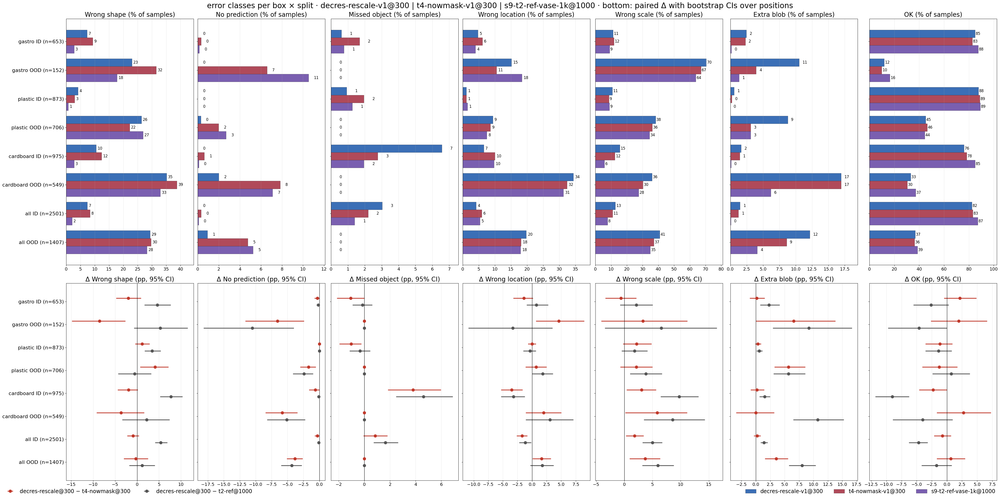

In [19]:
# every error class per box x split x run on the binary scores (DS); Wrong shape first. OK = primary OK (no error at all)
CLS = [("shape", "Wrong shape"), ("nopred", "No prediction"), ("missed", "Missed object"), ("loc", "Wrong location"), ("scale", "Wrong scale"), ("extra", "Extra blob"), ("ok", "OK")]
BS = [(f"{b} {g}", b, cs) for b in BOXES for g, cs in (("ID", ID_CATS), ("OOD", OOD_CATS))]

def rate(s, k):
    s = s[s.n_obj > 0]
    return 100 * (primary(s) == 7).mean() if k == "ok" else 100 * s[RATE[k]].mean()

rows = []
for g, b, cs in BS + [("all ID", None, ID_CATS), ("all OOD", None, OOD_CATS)]:
    for r in RUNS:
        s = cat(DS[r] if b is None else DS[r][DS[r].box == b], cs)
        rows.append({"box · split": g, "run": r, "n": int((s.n_obj > 0).sum()), **{n: rate(s, k) for k, n in CLS}})
BYBOX = pd.DataFrame(rows)
order = [g for g, _, _ in BS] + ["all ID", "all OOD"]
T = BYBOX.set_index(["box · split", "run"])[[n for _, n in CLS]].unstack("run").reindex(order)
T = T[[(n, r) for _, n in CLS for r in RUNS]]
T.columns = pd.MultiIndex.from_tuples([(n, short(r)) for n, r in T.columns])
T.insert(0, ("", "n"), BYBOX[BYBOX.run == NEW].set_index("box · split").n.reindex(order))
print(f"error rate, % of samples (non-empty targets) · {' | '.join(RUNS)}")
display(T.round(1))

# paired Δ with the 95% bootstrap CIs over positions from C2 (BOOT_RAW)
def ci(r, c): v, lo, hi = r[c]; return f"{v:+.1f} [{lo:+.1f},{hi:+.1f}]" + (" ★" if lo > 0 or hi < 0 else "")
GROUP = {f"{b} {g}": f"{b} {g}" for b in BOXES for g in ("ID", "OOD")} | {"all ID": "ID", "all OOD": "OOD"}
for a, b in PAIRS[:2]:
    D_ = pd.DataFrame([{"box · split": g, "pos": BOOT_RAW[(a, b)][GROUP[g]]["positions"], **{n: ci(BOOT_RAW[(a, b)][GROUP[g]], k) for k, n in CLS}} for g in order]).set_index("box · split")
    print(f"{a} − {b}: Δ error rate pp, paired, 95% bootstrap CI over positions (★ = excludes 0; positive = {short(a)} has more)"); display(D_)

# one wide chart: facet = error class, rows = box · split, grouped bars = run; right of it the paired Δ (pp) with CIs
fig, axes = plt.subplots(2, len(CLS), figsize=(44, 22), sharey=True, constrained_layout=True, gridspec_kw=dict(height_ratios=[1.25, 1]))
y = np.arange(len(order))
for ax, (k, n) in zip(axes[0], CLS):
    for i, r in enumerate(RUNS):
        v = T[(n, short(r))].to_numpy()
        ax.barh(y + (i - 1) * 0.27, v, 0.27, color=RUN_COLOR[i], edgecolor="#222", lw=0.4, label=r)
        for yy, vv in zip(y + (i - 1) * 0.27, v): ax.text(vv + 0.5, yy, f"{vv:.0f}", va="center", fontsize=12)
    ax.set_title(n + " (% of samples)", fontsize=20); ax.grid(axis="x", alpha=0.3); ax.set_xlim(0, 1.15 * np.nanmax(T[n].to_numpy()))
for ax, (k, n) in zip(axes[1], CLS):
    for j, (p, col) in enumerate(zip(PAIRS[:2], ("#C0392B", "#555555"))):
        v = np.array([BOOT_RAW[p][GROUP[g]][k] for g in order])
        ax.errorbar(v[:, 0], y + (j - 0.5) * 0.3, xerr=[v[:, 0] - v[:, 1], v[:, 2] - v[:, 0]], fmt="o", ms=9, lw=2.5, color=col, label=f"{short(p[0])} − {short(p[1])}")
    ax.axvline(0, color="k", lw=1); ax.set_title(f"Δ {n} (pp, 95% CI)", fontsize=20); ax.grid(axis="x", alpha=0.3)
for ax in axes[:, 0]: ax.set_yticks(y, [f"{g} (n={T.loc[g, ('', 'n')]})" for g in order], fontsize=16)
axes[0, 0].invert_yaxis()
fig.legend(*axes[0, 0].get_legend_handles_labels(), loc="outside lower right", ncol=3, frameon=False, fontsize=17)
fig.legend(*axes[1, 0].get_legend_handles_labels(), loc="outside lower left", ncol=2, frameon=False, fontsize=17)
fig.suptitle(f"error classes per box × split · {' | '.join(RUNS)} · bottom: paired Δ with bootstrap CIs over positions", fontsize=24)
plt.show()

### Wrong shape, in depth
1. Which splits / categories carry the wrong shapes (sample rate, eval + the saved train-set eval).
2. Paired NEW vs BASE (and vs REF): the samples that are Wrong shape only under NEW, and what the other run output on them. "empty" = no pixel p > .08 anywhere; "Missing (some pixels)" = nb126 Missing with some pixels.
3. Distribution of the per-object shape score (found objects only; missing objects have no shape score, which is why a run that misses more can look better here).

Wrong shape rate % per box / split (eval ID+OOD + train), sorted by decres-rescale@300


run                                                             decres-rescale@300  t4-nowmask@300  t2-ref@1000  Δ NEW−BASE
box       split                          category      n   pos                                                             
gastro    soap-dispenser-sideways        rotated       18  6                 100.0           100.0        100.0         0.0
cardboard portable-charger               unseen-object 36  9                  97.2            94.4         94.4         2.8
plastic   soap-dispenser-sideways        rotated       28  7                  96.4            92.9         96.4         3.6
          portable-charger               unseen-object 40  10                 92.5            90.0         87.5         2.5
cardboard cylinder-200g                  cylinder      40  10                 60.0            65.0         57.5        -5.0
          cylinder-100g                  cylinder      36  9                  58.3            55.6         61.1         2.8
gastro    two-cubes                      multiple      42  14                 57.1            54.8         11.9         2.4
          cube-vase                      multiple      27  9                  55.6            40.7         11.1        14.8
cardboard soap-dispenser-rotated         rotated       100 25                 55.0            53.0         43.0         2.0
          cylinder-1000g                 cylinder      28  7                  53.6            28.6         32.1        25.0
          two-cubes                      multiple      79  20                 51.9            62.0         16.5       -10.1
plastic   cylinder-200g                  cylinder      35  9                  48.6            28.6         37.1        20.0
cardboard cylinder-500g                  cylinder      40  10                 47.5            50.0         32.5        -2.5
plastic   cube-shifted-lasers-3-backside unseen-laser  32  8                  40.6            18.8         25.0        21.9
          cube-vase                      multiple      32  8                  37.5            31.2          6.2         6.2
          two-cubes                      multiple      64  16                 35.9            18.8          4.7        17.2
gastro    coffee-pot                     unseen-object 24  8                  33.3            45.8          4.2       -12.5
plastic   cube-with-lid                  lid           32  8                  28.1            37.5         18.8        -9.4
cardboard cube-vase                      multiple      66  17                 22.7            36.4         13.6       -13.6
          vase-laser-shifted-4           unseen-laser  24  6                  20.8            20.8         45.8         0.0
plastic   coffee-pot                     unseen-object 343 86                 20.4            16.0         23.3         4.4
cardboard cube                           id            221 56                 20.4            20.4          2.3         0.0
          cube-rotated                   rotated       20  5                  20.0            55.0         10.0       -35.0
plastic   cylinder-100g                  cylinder      28  7                  17.9            10.7         17.9         7.1
cardboard vase-with-lid                  lid           36  9                  16.7            19.4         11.1        -2.8

Wrong shape rate % per category (boxes pooled)


run,decres-rescale@300,t4-nowmask@300,t2-ref@1000,n
category,,,,
rotated,62.7,65.1,54.2,166
multiple,41.9,41.6,11.3,310
cylinder,33.5,32.9,32.3,331
unseen-object,27.8,28.4,29.5,550
lid,19.3,24.1,12.0,83
unseen-laser,13.5,9.4,13.5,192
unseen-speaker,4.7,8.2,3.5,85
train,3.9,1.6,1.0,11050
id,2.6,3.6,0.7,2191


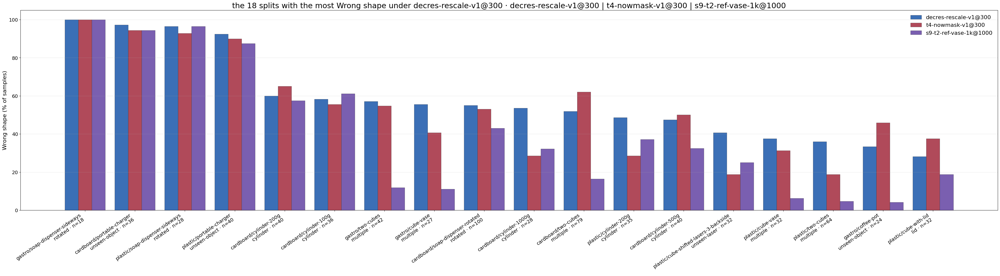

In [20]:
# Wrong shape, deeper. (1) which splits / objects have the most wrong shapes
EVAL_CATS = ID_CATS + OOD_CATS
rows = []
for r in RUNS:
    s = DS[r][(DS[r].n_obj > 0) & DS[r].category.isin(EVAL_CATS + ["train"])]
    for (b, sp, c), x in s.groupby(["box", "split", "category"]):
        rows.append({"box": b, "split": sp, "category": c, "run": short(r), "n": len(x), "pos": x.position_id.nunique(), "Wrong shape %": 100 * x.r_shape.mean(),
                     "primary Wrong shape %": 100 * (primary(x) == 4).mean(), "mean shape score": x["shape"].mean()})
SHP = pd.DataFrame(rows)
W_ = SHP.pivot_table(index=["box", "split", "category", "n", "pos"], columns="run", values="Wrong shape %")[[short(r) for r in RUNS]]
W_["Δ NEW−BASE"] = W_[short(NEW)] - W_[short(BASE)]
print("Wrong shape rate % per box / split (eval ID+OOD + train), sorted by", short(NEW)); display(W_.sort_values(short(NEW), ascending=False).head(25).round(1))

# by category (all boxes pooled)
C_ = SHP.assign(k=SHP["Wrong shape %"] * SHP.n).groupby(["category", "run"]).agg(n=("n", "sum"), k=("k", "sum"))
C_ = (C_.k / C_.n).unstack("run")[[short(r) for r in RUNS]].assign(n=C_.n.xs(short(NEW), level="run"))
print("Wrong shape rate % per category (boxes pooled)"); display(C_.sort_values(short(NEW), ascending=False).round(1))

top = W_.sort_values(short(NEW), ascending=False).head(18)
fig, ax = plt.subplots(figsize=(40, 11), constrained_layout=True)
x = np.arange(len(top))
for i, r in enumerate(RUNS):
    ax.bar(x + (i - 1) * 0.27, top[short(r)], 0.27, color=RUN_COLOR[i], edgecolor="#222", lw=0.4, label=r)
ax.set_xticks(x, [f"{b}/{sp}\n{c} · n={n}" for b, sp, c, n, _ in top.index], rotation=35, ha="right", fontsize=14)
ax.set_ylabel("Wrong shape (% of samples)"); ax.legend(frameon=False, fontsize=16); ax.grid(axis="y", alpha=0.3)
ax.set_title(f"the 18 splits with the most Wrong shape under {NEW} · {' | '.join(RUNS)}", fontsize=22)
plt.show()

n  shape A %  shape B %  new (A only)  lost (B only)  net  new where B empty %  new where B Missing (any) %  B Missing → A any shape-wrong  new: A iou08  new: B iou08  new: A area08 med
pair                                group                                                                                                                                                                                              
decres-rescale@300 − t4-nowmask@300 ID     2501       7.44       8.32           103            125  -22                 1.94                        18.45                             25          0.41          0.36               1.44
                                    OOD    1407      29.42      29.71           143            147   -4                13.29                        16.78                             24          0.29          0.30               1.20
decres-rescale@300 − t2-ref@1000    ID     2501       7.44       2.04           170             35  135                 0.59                         8.82                             15          0.37          0.39               1.45
                                    OOD    1407      29.42      28.29           161            145   16                 9.94                        11.18                             18          0.32          0.34               1.39

decres-rescale@300 vs t4-nowmask@300 ID: the 103 samples that are Wrong shape only under decres-rescale@300 were, under t4-nowmask@300: OK 34 (33%), Wrong location 27 (26%), Wrong scale 23 (22%), Missing (some pixels) 17 (17%), empty (no p>.08) 2 (2%)
decres-rescale@300 vs t4-nowmask@300 OOD: the 143 samples that are Wrong shape only under decres-rescale@300 were, under t4-nowmask@300: OK 58 (41%), Wrong location 37 (26%), Wrong scale 20 (14%), empty (no p>.08) 19 (13%), Missing (some pixels) 5 (3%), Extra blob 4 (3%)
decres-rescale@300 vs t2-ref@1000 ID: the 170 samples that are Wrong shape only under decres-rescale@300 were, under t2-ref@1000: OK 78 (46%), Wrong location 50 (29%), Wrong scale 27 (16%), Missing (some pixels) 14 (8%), empty (no p>.08) 1 (1%)
decres-rescale@300 vs t2-ref@1000 OOD: the 161 samples that are Wrong shape only under decres-rescale@300 were, under t2-ref@1000: OK 77 (48%), Wrong location 38 (24%), Wrong scale 26 (16%), empty (no p>.08) 16 (10%), Extra blob 2 

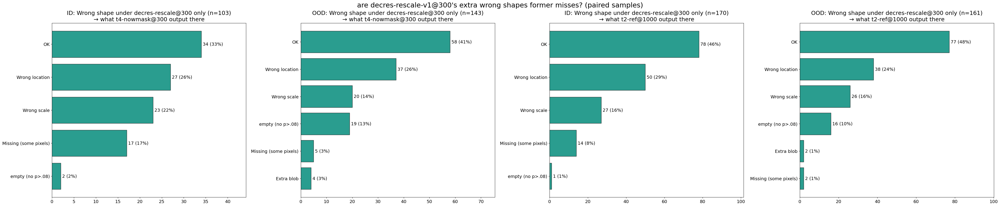

In [21]:
# (2) are NEW's extra wrong shapes samples where BASE painted nothing (misses turned into blobs)?
# paired on the same sample: "new" = Wrong shape under A but not B. What did B output there?
def b_state(m):
    """B's output on a sample: empty (no pixel p > .08 anywhere), missed (pixels, but nb126 Missing), else B's primary class"""
    pb = pd.Series(np.array(NAMES)[m.pb], index=m.index).replace({"Wrong location (mirrored)": "Wrong location"})
    return np.where(m.area08_b == 0, "empty (no p>.08)", np.where(m.missing_b > 0, "Missing (some pixels)", pb))

rows, TRANS = [], {}
for a, b in PAIRS[:2]:
    for g, cs in (("ID", ID_CATS), ("OOD", OOD_CATS)):
        sa, sb = cat(DS[a], cs), cat(DS[b], cs)
        m = sa[sa.n_obj > 0].assign(pa=lambda s: primary(s)).merge(sb.assign(pb=lambda s: primary(s)), on=K, suffixes=("_a", "_b"))
        new, lost = m[(m.r_shape_a == 1) & (m.r_shape_b != 1)], m[(m.r_shape_b == 1) & (m.r_shape_a != 1)]
        st = pd.Series(b_state(new)).value_counts()
        TRANS[(a, b, g)] = st
        rows.append({"pair": f"{short(a)} − {short(b)}", "group": g, "n": len(m), f"shape A %": 100 * m.r_shape_a.mean(), f"shape B %": 100 * m.r_shape_b.mean(),
                     "new (A only)": len(new), "lost (B only)": len(lost), "net": len(new) - len(lost),
                     "new where B empty %": 100 * (new.area08_b == 0).mean(), "new where B Missing (any) %": 100 * ((new.area08_b == 0) | (new.missing_b > 0)).mean(),
                     "B Missing → A any shape-wrong": int(((m.missing_b > 0) & (m.r_shape_a == 1)).sum()),
                     "new: A iou08": new.iou08_a.mean(), "new: B iou08": new.iou08_b.mean(), "new: A area08 med": new.area08_a.median()})
MISS2BLOB = pd.DataFrame(rows).set_index(["pair", "group"])
display(MISS2BLOB.round(2))
for (a, b, g), st in TRANS.items():
    print(f"{short(a)} vs {short(b)} {g}: the {st.sum()} samples that are Wrong shape only under {short(a)} were, under {short(b)}: " + ", ".join(f"{k} {v} ({100 * v / st.sum():.0f}%)" for k, v in st.items()))

fig, axes = plt.subplots(1, 4, figsize=(44, 9), constrained_layout=True)
for ax, ((a, b, g), st) in zip(axes, TRANS.items()):
    ax.barh(st.index[::-1], st.values[::-1], color="#2A9D8F", edgecolor="#222")
    for yy, v in enumerate(st.values[::-1]): ax.text(v, yy, f" {v} ({100 * v / st.sum():.0f}%)", va="center", fontsize=14)
    ax.set_title(f"{g}: Wrong shape under {short(a)} only (n={st.sum()})\n→ what {short(b)} output there", fontsize=18); ax.set_xlim(0, 1.3 * st.max())
fig.suptitle(f"are {NEW}'s extra wrong shapes former misses? (paired samples)", fontsize=22)
plt.show()

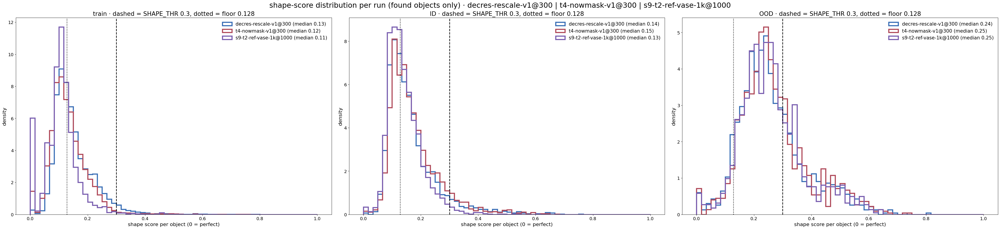

objects  missing objects (no score)  median    p75    p90   mean  > 0.3 %
group run                                                                                          
train decres-rescale@300    11928                         315   0.134  0.182  0.242  0.152    3.664
      t4-nowmask@300        12211                          32   0.122  0.163  0.212  0.132    1.482
      t2-ref@1000           12242                           1   0.106  0.132  0.170  0.107    0.890
ID    decres-rescale@300     2735                          76   0.143  0.195  0.275  0.167    7.678
      t4-nowmask@300         2748                          63   0.152  0.209  0.282  0.174    8.115
      t2-ref@1000            2774                          37   0.131  0.172  0.219  0.143    1.875
OOD   decres-rescale@300     1394                          13   0.242  0.317  0.435  0.263   29.699
      t4-nowmask@300         1340                          67   0.249  0.320  0.447  0.271   31.194
      t2-ref@1000            1333                          74   0.249  0.320  0.429  0.264   29.857

In [22]:
# (3) distribution of the shape score (1 − soft IoU after moving / zooming the prediction onto the object), per object, non-missing objects
rows = []
fig, axes = plt.subplots(1, 3, figsize=(44, 10), constrained_layout=True)
for ax, (g, cs) in zip(axes, (("train", ["train"]), ("ID", ID_CATS), ("OOD", OOD_CATS))):
    for i, r in enumerate(RUNS):
        o = DO[r][DO[r].category.isin(cs) & (DO[r].missing == 0)]
        v = o["shape"].dropna().to_numpy()
        ax.hist(v, bins=60, range=(0, 1), histtype="step", lw=3.5, color=RUN_COLOR[i], density=True, label=f"{r} (median {np.median(v):.2f})")
        rows.append({"group": g, "run": short(r), "objects": len(v), "missing objects (no score)": int((DO[r].category.isin(cs) & (DO[r].missing == 1)).sum()),
                     "median": np.median(v), "p75": np.percentile(v, 75), "p90": np.percentile(v, 90), "mean": v.mean(), f"> {SHAPE_THR} %": 100 * (v > SHAPE_THR).mean()})
    ax.axvline(SHAPE_THR, color="k", ls="--", lw=2); ax.axvline(SHAPE_FLOOR, color="k", ls=":", lw=2)
    ax.set_xlabel("shape score per object (0 = perfect)"); ax.set_ylabel("density"); ax.legend(frameon=False, fontsize=15)
    ax.set_title(f"{g} · dashed = SHAPE_THR {SHAPE_THR}, dotted = floor {SHAPE_FLOOR:.3f}", fontsize=19)
fig.suptitle(f"shape-score distribution per run (found objects only) · {' | '.join(RUNS)}", fontsize=23)
plt.show()
SHAPE_DIST = pd.DataFrame(rows).set_index(["group", "run"]); display(SHAPE_DIST.round(3))

### Findings (I)
All rates are % of samples, NEW / BASE / REF. ★ = 95% CI excludes 0.
- **Wrong shape per box:**

  | box | ID | OOD |
  |---|---|---|
  | gastro | 7.4 / 9.3 / 2.8 | 23.0 / 31.6 / 17.8 |
  | plastic | 4.1 / 3.0 / 0.7 | 26.3 / 22.2 / 26.9 |
  | cardboard | 10.5 / 12.4 / 2.8 | 35.2 / 38.8 / 33.0 |

- **NEW − BASE**: gastro OOD −8.6 pp★, plastic OOD +4.1★, the rest n.s. Pooled ID −0.9, OOD −0.3 (both n.s.).
- **NEW − REF**: worse on every ID box (gastro +4.6★, plastic +3.4★, cardboard +7.7★; pooled ID +5.4★). OOD +1.1 (n.s.).
- **Where**:
  - rotated 63 / 65 / 54;
  - multiple 42 / 42 / 11, REF's clear win: it draws both cubes as cubes;
  - cylinder 34 / 33 / 32;
  - lid 19 / 24 / 12.
  - On train, NEW is 3.9% vs 1.6 / 1.0.
- **Misses into blobs no longer shows up as Wrong shape.** OOD: 143 samples are shape-wrong only under NEW, and 147 only under BASE (net −4). Just 24 of the 143 were Missing under BASE. The soft-mass version's "+74, matching BASE's misses" came from stray mass dragging the COM and the shape. The same trade now shows up on OOD as NEW − BASE: No prediction −3.8★, Wrong scale +3.7★, Extra blob +3.6★, Wrong location +1.6★.
- **Shape-score distribution** (found objects): OOD median .242 / .249 / .249, p90 .435 / .447 / .429. The soft version's heavy NEW tail (p90 .89) is gone. ID median .143 / .152 / .131, train .134 / .122 / .106. The floor (truth shifted 0.5 px, binarized) has median .128.
- **Missing, split:**
  - No prediction: ID 0.0 / 0.3 / 0.1, OOD 0.9 / 4.8 / 5.3.
  - Missed object: ID 3.0 / 2.2 / 1.4, with cardboard ID 6.6 / 2.8 / 1.9. OOD is 0 for all runs, since every OOD split has one object.
  - NEW − BASE: No prediction OOD −3.8★; Missed object ID +0.8 (n.s.), cardboard +3.8★.
  - NEW − REF: Missed object ID +1.6★ (cardboard +4.6★).
  - NEW almost never paints nothing, but it drops the second object more often.

## Verdict
All three runs are scored on the same 4,672 eval samples: 2,501 ID, 1,407 OOD with a non-empty target, and 310 with two objects. Eval is eager. Δ = A − B, paired, with 95% bootstrap CIs over positions. ★ marks a CI that excludes 0. NEW = decres-rescale-v1@300, BASE = t4-nowmask-v1@300, REF = s9-t2-ref-vase-1k@1000. The error classes are scored on the binary mask b = p > .08.

**0. Scoring.** The original nb126 classes used soft mass. NEW never outputs an exact 0: it leaves a ~1e-3 haze over 98% of the grid, holding 5.2% of Σp (BASE 1.2%, REF 1.3%). That haze, and stray blobs inside a cell, inflated NEW's Wrong shape to 40% and moved its centroids. With binary classes and one main component per object, the haze cannot matter and strays are counted as Extra blob. iou08, iou50, biou and area never depended on this.

**1. Where NEW really improves on BASE.**
- Pooled iou08: ID +.026 [.021, .031]★, OOD +.014 [.007, .021]★.
- iou50 gains more than iou08: ID +.045★, OOD +.016★. Boundary IoU: ID +.022★. So the gain is not a low-threshold artifact.
- Under-painting falls 7.2 → 1.7% of ID samples. ID Wrong location −1.7 pp★, and No prediction drops to ~0 (−0.3★ ID, −3.8★ OOD).
- By box: gastro ID +.043★, cardboard ID +.028★, cardboard OOD +.038★, plastic ID +.011★. **Plastic OOD is a tie: −.003 [−.010, .004].**
- By category: multiple +.041★, unseen-position +.028★ (OK +7.1 pp★), unseen-angle +.057★, unseen-object +.017★, control +.041★. Unseen-speaker is a tie: −.005 [−.035, .024].

**2. Where the higher IoU hides a worse behavior.**
- **(a) Primary OK does not improve:** ID 82.4 vs 83.2% (−0.7, n.s.), OOD 36.9 vs 36.2% (+0.6, n.s.). NEW's extra iou08 comes from covering objects more and missing fewer, not from more fully correct samples.
- **(b) Misses become wrong-size / misplaced blobs (OOD).** No prediction falls 4.8 → 0.9%, while Wrong scale +3.7★, Extra blob +3.6★ and Wrong location +1.6★ rise.
  - Cylinder: No prediction −7.3★, location +4.8★, scale +13.6★, iou08 +.006 (n.s.).
  - Lid: No prediction −16.9★, location +8.4 (n.s.).
  - NEW paints something where BASE painted nothing. That earns iou08 credit, but often too big or in the wrong place.
- **(c) Bigger masks.**
  - Over-painted (area > 1.25): ID 26% vs 14%, OOD 48% vs 35%.
  - Median area08: ID 1.16 vs 1.08, OOD 1.22 vs 1.00.
  - In the classes this is Wrong scale: ID 12.7% vs 10.9% (+1.8★), and 7.7% for REF (+5.0★). At p > .5 the masks stay crisp (area50 median 1.01).
- **(d) Multi-object (310 samples, 84 positions).** The +.041 iou08 comes from covering the found object better: the stronger object's cov08 is .83 vs .69. NEW does not find the second object more often:
  - all objects found: 75% vs 82% for BASE (−6.8 pp, n.s.) and **89% for REF (−13 pp [−20, −6]★)**;
  - Missed object ID: 3.0 / 2.2 / 1.4%, and in cardboard 6.6 / 2.8 / 1.9%;
  - REF draws both objects in the right shape: multiple Wrong shape is 11% for REF vs 42% for NEW and BASE.
- **(e) Train fit.** NEW's train iou08 is .79, against .87 for BASE and .91 for REF. It generalizes better than it fits and is not saturated. ID was still rising at ep300.

**3. Against REF (t2-ref, 1k epochs).**
- REF is a strong reference once re-evaluated eager: .695 / .386. Its compiled logs had biased it low. It beats BASE on ID iou08 (+.017★) and on multiple.
- NEW beats REF on iou08 by only +.009 [.003, .014]★ ID and +.011 [.002, .019]★ OOD. That is about 2× the ±.005 pooled noise.
- REF has more fully correct samples on ID: OK 87.1 vs 82.4% (NEW − REF −4.7★).
- NEW − REF on ID: Wrong scale +5.0★, Wrong shape +5.4★, Missed object +1.6★, Extra blob +1.4★. On OOD: No prediction −4.3★, Wrong scale +6.0★, Extra blob +8.0★.
- By box, NEW vs REF: gastro +.023★ ID / +.028★ OOD; cardboard OOD +.016★; **plastic ID +.003 and cardboard ID +.004 are ties**.
- Per category, the one large NEW win is unseen-speaker, +.080★. That is REF's weak spot: BASE also beats REF there by +.085★.
- Classes each model fails on:
  - REF: No prediction on OOD (5.3%) and unseen-speaker.
  - BASE: under-painting (ID under 7.2%) and No prediction on OOD (4.8%).
  - NEW: oversized and extra blobs on OOD, and dropping the second object.

**4. Robustness.** The pooled iou gains over BASE are 3–5σ. The gains over REF are about 2σ. Single seed. Per-category rows have 3–140 positions (unseen-speaker 85, unseen-angle 27, lid 22, broken 3), so only differences above ~.03–.05 or ~10 pp mean anything there.

## Paper figure · error classes, worst offenders
`error_grid(run, ep, S, O, picks=None)` draws 5 rows × 4 panels for one run:
- **Rows**: No prediction, Missed object, Wrong location (mirrored included), Wrong scale, Wrong shape. The shape row has primary Wrong shape only, and only samples whose prediction overlaps the truth (iou08 > 0): the right object, drawn the wrong shape. Extra blob is never the primary class on a non-empty target, so it gets no row.
- **Classes**: each run's own binary classes (`DS` / `DO`), using primary-class samples (nb126 priority). Non-empty targets only, from train, ID, OOD and other.
- **Severity** uses nb126's own quantities:
  - No prediction / Missed object: lowest min_k Σp/|T_k|;
  - Location: largest ‖COM − c_k‖/D;
  - Scale: largest |log Σp/|T_k||;
  - Shape: largest shape score.
- **Minimum size**: every row uses only samples whose true objects are all at least 12 px (MIN_AREA). A 2–4 px cylinder-100g is unreadable at whole-box scale, and its scores are noise.
- **Diverse pick**: the pool is the top 20% by severity (at least 5n, one per position). It is filled greedily: highest first, then the sample adding the most unseen (box ×2, split ×2, 1 vs 2+ objects, speaker), with severity breaking ties. One sample per position in the whole figure, and at most one train sample per row. A row with fewer than 4 candidates shows what exists; the cell prints the candidate counts.
- **Shared figure**: `picks=` draws exactly those samples. It is used to draw decres-rescale-v1's picks for every run.
- **Excluded**: `<exp>/bad_samples/`, `src9/exclude.csv` capture glitches, nb91's broken gastro cylinder masks 1242 / 1244, **gastro cube-with-lid 1255** (truth = the whole box, 4069 / 4096 px, no without-lid twin), and any truth covering > 25% of the grid.
- **Panel**: the whole box, resampled to one panel size (height / width 0.8) at the figure's 300 dpi.
  - background: the box photo (02_cropped_overhead), LANCZOS-resized, at 40% saturation and lightened toward white. With-lid samples show their without-lid twin, whose mask the truth uses;
  - prediction: p > .08 (utils.THR, the iou08 threshold), orange fill at 50% plus a thin orange edge;
  - ground truth: blue outline;
  - both are traced at panel resolution on the nearest-upsampled 64×64 masks (as viz2/render.py `thumb()` does), so edges stay crisp.
- **Text**: only the tag "a1 · split" (train, single-obj (control too), multi-obj, unseen position / speaker / angle / object / laser, cylinder, lid, rotated, broken glass), placed in the corner that covers the fewest mask pixels.
- **Output**: notebooks/plots/nb132_error_grid_<run>.{pdf,png} + _ids.txt (panel → sample), and nb132_error_grid_shared_<run>.{pdf,png} + nb132_error_grid_shared_ids.txt.

In [23]:
# bad samples kept out of the paper figure: <exp>/bad_samples/ (moved out of samples/, so never scored) + src9/exclude.csv (dropped by the dataset)
# + nb91's known broken masks still in eval (gastro cylinder 1242 / 1244) + any position whose truth covers > 25% of the grid
# (found here: gastro cube-with-lid 1255, truth = the whole box, 4069 of 4096 px: it has no without-lid twin)
import csv, json, cv2
from PIL import Image
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
from score import sample_dir
from dataset import EXPERIMENTS, load_meta

BAD_POS = {("2026_09_27_gastronorm_four_objs", 1242), ("2026_09_27_gastronorm_four_objs", 1244), ("2026_09_27_gastronorm_four_objs", 1255)}  # 1255: cube-with-lid, truth = whole box
for d in EXPERIMENTS.glob("*/bad_samples/*/metadata.jsonl"): BAD_POS.add((d.parent.parent.parent.name, int(load_meta(d.parent)["position_id"])))
for r in RUNS[:1]:
    big = DO[r][DO[r].area > 0.25 * H * W]
    BAD_POS |= set(zip(big.experiment, big.position_id))
    print("truth > 25% of the grid:", sorted(set(zip(big.box, big.split, big.position_id, big.area))))
BAD_SID = {(r["experiment"], r["sample_id"]) for r in csv.DictReader(open(ROOT / "src9/exclude.csv"))}
print(f"excluded: {len(BAD_POS)} positions (bad_samples/ + broken masks), {len(BAD_SID)} capture glitches (exclude.csv, by sample dir name)")

truth > 25% of the grid: [('gastro', 'cube-with-lid', 1255, 4069.0)]
excluded: 77 positions (bad_samples/ + broken masks), 93 capture glitches (exclude.csv, by sample dir name)


In [24]:
def error_grid(run, ep, S, O, n=4, out=None, picks=None, top_frac=0.2, ASPECT=0.8, DPI=300, MIN_AREA=12):
    """paper figure for one run: 5 rows (No prediction / Missed object / Wrong location / Wrong scale / Wrong shape) x n panels, the whole box in every panel.
    picks=None: this run's diverse worst offenders from its scores S / O; else draw exactly those samples (shared figure).
    Panel = one raster at the figure's pixel size: faded photo (LANCZOS), GT = blue outline, prediction p > THR = orange fill + edge, both traced on the
    nearest-upsampled 64x64 masks (as viz2/render.py thumb()). Saves out.{pdf,png}; returns (fig, picks with this run's iou08)"""
    import matplotlib
    ROWS = ["No prediction", "Missed object", "Wrong location", "Wrong scale", "Wrong shape"]
    GT, PR = "#0072B2", "#E69F00"
    if picks is None:
        # per-sample severity from nb126's own quantities (per-object max / min over the sample's objects)
        s = S[S.n_obj > 0].drop_duplicates(K).copy()
        s = s[[(e, p) not in BAD_POS and (e, sample_dir(e, i, p, k).name) not in BAD_SID for e, i, p, k in zip(s.experiment, s.sample_id, s.position_id, s.speaker)]]
        o = O.assign(cov=O.mass / O.area, logr=np.abs(np.log(np.maximum(O.mass, 1e-9) / O.area)).where(O.missing == 0))
        s = s.merge(o.groupby(K).agg(cov=("cov", "min"), loc_max=("loc", "max"), logr=("logr", "max"), shape_max=("shape", "max"), area_min=("area", "min")).reset_index(), on=K, how="left")
        s = s[s.area_min >= MIN_AREA]   # every true object >= MIN_AREA px (a 2-4 px cylinder-100g is unreadable at whole-box scale)
        s["cls"] = primary(s)
        # (candidates, severity): no prediction / missed object = lowest coverage min_k Σp/|T_k|; location = centroid error; scale = |log mass ratio|;
        # shape = primary Wrong shape that overlaps the truth (iou08 > 0: the right object, drawn the wrong shape), severity = shape score
        CAND = [(s.cls == 0, -s["cov"]), (s.cls == 1, -s["cov"]), (s.cls.isin([2, 3]), s.loc_max), (s.cls == 4, s.logr), ((s.cls == 5) & (s.iou08 > 0), s.shape_max)]
        # diverse pick: pool = top top_frac by severity (>= 5n, one per position); greedy: highest severity first, then the sample adding the most
        # unseen (box x2, split x2, 1 vs 2+ objects, speaker), ties -> severity. One sample per position in the whole figure, at most one train sample
        # per row. A row with fewer than n candidates shows what exists
        WT = {"box": 2, "split": 2, "multi": 1, "spk": 1}
        att = lambda x: {("box", x.box), ("split", x.category), ("multi", x.n_obj > 1), ("spk", x.speaker)}
        used, rows = set(), []
        for r, (m, sev) in enumerate(CAND):
            c = s[m].assign(sev=sev[m]).sort_values("sev", ascending=False).drop_duplicates(["experiment", "position_id"])
            c = c[[(e, p) not in used for e, p in zip(c.experiment, c.position_id)]]
            print(f"{run} · {ROWS[r]}: {len(c)} candidate positions ({(c.category == 'train').sum()} train)")
            c = c.head(max(int(np.ceil(top_frac * len(c))), 5 * n))
            seen = set()
            for k in range(n):
                if not len(c): break
                gain = np.array([sum(WT[a] for a, _ in att(x) - seen) for x in c.itertuples()])
                x = c.iloc[np.lexsort((-c.sev.to_numpy(), -gain))[0] if k else 0]
                rows.append(dict(x, row=r, col=k)); seen |= att(x); used.add((x.experiment, x.position_id))
                c = c[((c.experiment != x.experiment) | (c.position_id != x.position_id)) & ((c.category != "train") | (x.category != "train"))]
        picks = pd.DataFrame(rows)
    picks = picks.copy()

    # predictions of the picked samples (saved eval + train-set eval of this run / epoch)
    want, P = set(map(tuple, picks[["experiment", "sample_id", "position_id", "speaker"]].to_numpy())), {}
    hist = ROOT / "runs" / run / "outputs_history"
    for pt in sorted(hist.glob(f"eval/*/*/ep{ep:04d}-ba*.pt")) + sorted(hist.glob(f"train/ep{ep:04d}-ba*.pt")):
        d = torch.load(pt, weights_only=False, map_location="cpu"); info = d["info"]
        for i in range(len(d["mask_pred"])):
            k = (info["experiment"][i], int(info["sample_id"][i]), int(info["position_id"][i]), int(info["speaker"][i]))
            if k in want: P[k] = d["mask_pred"][i].float().numpy()

    # panels of one size / aspect (height / width = ASPECT, every box resampled to it): figure height from the panel width; legend strip on top
    left, right, gap, leg = 0.045, 0.998, 0.025, 0.22
    pw = 7 * (right - left) / (n + (n - 1) * gap)
    fh = pw * ASPECT * (len(ROWS) + (len(ROWS) - 1) * gap) + leg + 0.02
    fig, axes = plt.subplots(len(ROWS), n, figsize=(7, fh), squeeze=False)
    fig.subplots_adjust(left=left, right=right, top=1 - leg / fh, bottom=0.02 / fh, wspace=gap, hspace=gap)
    PXW = round(pw * DPI); PXH = round(pw * ASPECT * DPI)                      # one panel in device pixels at DPI
    rgb = lambda c: np.array(matplotlib.colors.to_rgb(c)) * 255
    TAG = {"train": "train", "id": "single-obj", "multiple": "multi-obj", "unseen-position": "unseen position", "unseen-speaker": "unseen speaker",
           "unseen-angle": "unseen angle", "unseen-object": "unseen object", "unseen-rotated-object": "unseen object", "unseen-laser": "unseen laser",
           "cylinder": "cylinder", "lid": "lid", "rotated": "rotated", "control": "single-obj", "broken": "broken glass"}
    for ax in axes.flat: ax.set_axis_off()
    for r, name in enumerate(ROWS): axes[r, 0].text(-0.04, 0.5, name, transform=axes[r, 0].transAxes, rotation=90, ha="right", va="center", fontsize=8, fontweight="bold")
    ious = []
    for x in picks.itertuples():
        ax, k = axes[x.row, x.col], (x.experiment, x.sample_id, x.position_id, x.speaker)
        d = sample_dir(*k)
        if (tw := load_meta(d).get("without_lid_position_id")) is not None:   # truth comes from the without-lid twin: show its photo too
            d = sample_dir(x.experiment, -1, tw, x.speaker)
            if not d.exists(): d = next(q for q in (EXPERIMENTS / x.experiment / "samples").iterdir() if (m := load_meta(q)).get("position_id") == tw and m.get("speaker") == x.speaker)
        img = np.asarray(Image.open(d / "image/02_cropped_overhead.png").convert("RGB").resize((PXW, PXH), Image.LANCZOS), np.float32)
        g = img.mean(-1, keepdims=True)
        arr = 255 - 0.6 * (255 - (g + 0.4 * (img - g)))                        # 40% saturation, then 40% of the way to white
        y = truth(*k, H, W) > 0.5; b = P[k] > THR
        ious.append((b & y).sum() / max((b | y).sum(), 1))
        up = lambda m: np.asarray(Image.fromarray(m.astype(np.uint8) * 255).resize((PXW, PXH), Image.NEAREST)) > 127
        Y, B = up(y), up(b)
        arr[B] = 0.5 * rgb(PR) + 0.5 * arr[B]
        arr = np.ascontiguousarray(arr.clip(0, 255).astype(np.uint8))
        for M, col, t in ((B, PR, 2), (Y, GT, 4)):
            cs, _ = cv2.findContours(M.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
            cv2.drawContours(arr, cs, -1, tuple(int(v) for v in rgb(col)), t)
        ax.set_axis_on(); ax.set_xticks([]); ax.set_yticks([])
        for sp in ax.spines.values(): sp.set_linewidth(0.4); sp.set_color("#999")
        ax.imshow(arr, interpolation="none", aspect="auto")
        # tag "a1 · split" in the corner that covers the fewest mask pixels (label box ~ 45% x 13% of the panel)
        lab = f"{'abcde'[x.row]}{x.col + 1} · " + ("multi-obj" if x.n_obj > 1 and x.category != "train" else TAG.get(x.category, x.category))
        bw, bh = int(0.45 * PXW), int(0.13 * PXH)
        corners = [(0.025, 0.975, "left", "top", np.s_[:bh, :bw]), (0.975, 0.975, "right", "top", np.s_[:bh, -bw:]),
                   (0.025, 0.025, "left", "bottom", np.s_[-bh:, :bw]), (0.975, 0.025, "right", "bottom", np.s_[-bh:, -bw:])]
        tx, ty, ha, va, _ = min(corners, key=lambda c: (Y | B)[c[4]].sum())
        ax.text(tx, ty, lab, transform=ax.transAxes, ha=ha, va=va, fontsize=6, fontweight="bold", bbox=dict(boxstyle="square,pad=0.15", fc="white", ec="none", alpha=0.85))
    picks["iou08_here"] = ious
    fig.legend([Patch(fc="none", ec=GT, lw=1.3), Patch(fc=matplotlib.colors.to_rgba(PR, 0.5), ec=PR, lw=0.6)], ["Ground truth", "Prediction"],
               loc="upper center", ncol=2, fontsize=7, frameon=False, bbox_to_anchor=(0.5, 1), handlelength=1.6, columnspacing=1.5)
    if out:
        out = Path(out); out.parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(out.with_suffix(".pdf"), dpi=DPI); fig.savefig(out.with_suffix(".png"), dpi=DPI)
    return fig, picks

def grid_ids(picks, iou_cols):
    """plain panel -> sample list for the caption; iou_cols = {label: column}"""
    lines = []
    for _, x in picks.iterrows():
        grp = "train" if x.category == "train" else "ID" if x.category in ID_CATS else "OOD" if x.category in OOD_CATS else "other"
        lines.append(f"{'abcde'[x.row]}{x.col + 1}\t{x.experiment}/{sample_dir(x.experiment, x.sample_id, x.position_id, x.speaker).name}"
                     f"\tpos {x.position_id}\tspk {x.speaker}\t{grp} {x.category}/{x.split}\t{x.n_obj} obj\t" + "\t".join(f"IoU {l} {x[c]:.2f}" for l, c in iou_cols.items()))
    return "\n".join(lines)

decres-rescale-v1 · No prediction: 5 candidate positions (0 train)
decres-rescale-v1 · Missed object: 137 candidate positions (100 train)
decres-rescale-v1 · Wrong location: 171 candidate positions (20 train)
decres-rescale-v1 · Wrong scale: 680 candidate positions (369 train)
decres-rescale-v1 · Wrong shape: 241 candidate positions (90 train)


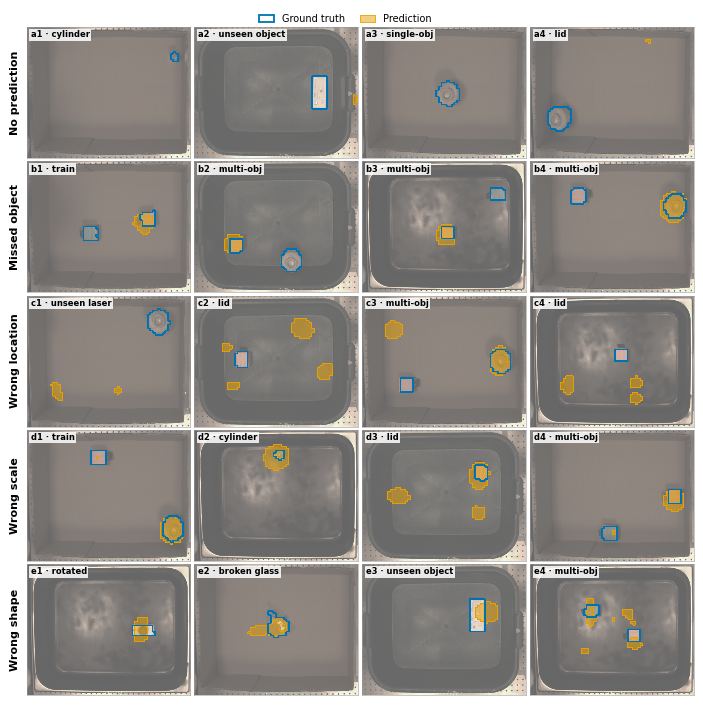

decres-rescale-v1@300 · panel -> sample (row-major; mask p > 0.08, classes on b = p > 0.08)
a1	2026_10_11_cardboard_four_objs/004321-5	pos 4321	spk 5	OOD cylinder/cylinder-500g	1 obj	IoU decres-rescale-v1@300 0.00
a2	2026_10_05_green_plastic_four_objs/002873-7	pos 2873	spk 7	OOD unseen-object/portable-charger	1 obj	IoU decres-rescale-v1@300 0.00
a3	2026_10_11_cardboard_four_objs/004715-3	pos 4715	spk 3	other control/vase-without-lid	1 obj	IoU decres-rescale-v1@300 0.00
a4	2026_10_11_cardboard_four_objs/004725-3	pos 4725	spk 3	OOD lid/vase-with-lid	1 obj	IoU decres-rescale-v1@300 0.00
b1	2026_10_11_cardboard_four_objs/004275-7	pos 4275	spk 7	train train/train	2 obj	IoU decres-rescale-v1@300 0.28
b2	2026_10_05_green_plastic_four_objs/002795-5	pos 2795	spk 5	ID multiple/cube-vase	2 obj	IoU decres-rescale-v1@300 0.25
b3	2026_09_27_gastronorm_four_objs/005609	pos 1123	spk 1	ID multiple/two-cubes	2 obj	IoU decres-rescale-v1@300 0.31
b4	2026_10_11_cardboard_four_objs/004078-3	pos 4078	spk 3	I

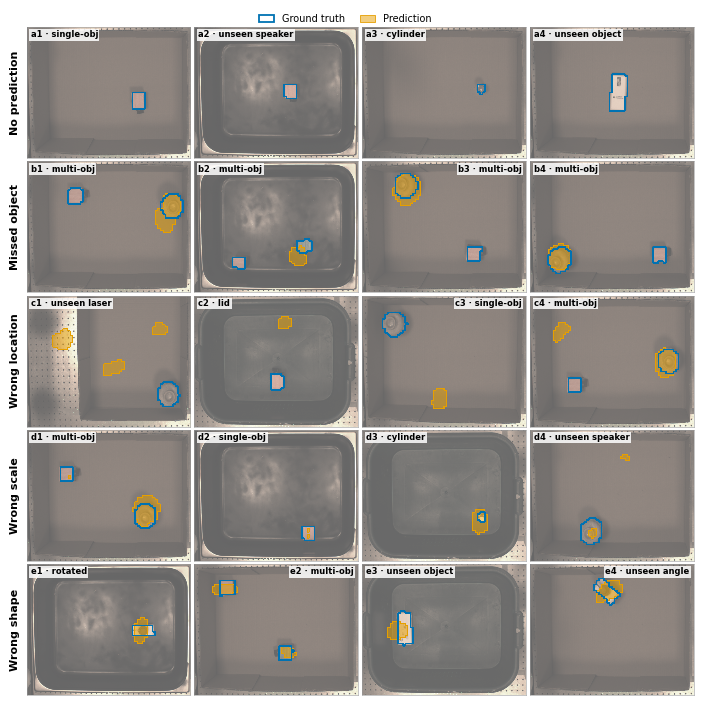

t4-nowmask-v1@300 · panel -> sample (row-major; mask p > 0.08, classes on b = p > 0.08)
a1	2026_10_11_cardboard_four_objs/003147-5	pos 3147	spk 5	ID id/cube	1 obj	IoU t4-nowmask-v1@300 0.00
a2	2026_09_27_gastronorm_four_objs/000268	pos 54	spk 4	OOD unseen-speaker/cube-unseen-speaker-unseen	1 obj	IoU t4-nowmask-v1@300 0.00
a3	2026_10_11_cardboard_four_objs/004331-3	pos 4331	spk 3	OOD cylinder/cylinder-500g	1 obj	IoU t4-nowmask-v1@300 0.00
a4	2026_10_11_cardboard_four_objs/004467-1	pos 4467	spk 1	OOD unseen-object/portable-charger	1 obj	IoU t4-nowmask-v1@300 0.00
b1	2026_10_11_cardboard_four_objs/004078-3	pos 4078	spk 3	ID multiple/cube-vase	2 obj	IoU t4-nowmask-v1@300 0.39
b2	2026_09_27_gastronorm_four_objs/005659	pos 1133	spk 1	ID multiple/two-cubes	2 obj	IoU t4-nowmask-v1@300 0.08
b3	2026_10_11_cardboard_four_objs/004132-7	pos 4132	spk 7	ID multiple/cube-vase	2 obj	IoU t4-nowmask-v1@300 0.48
b4	2026_10_11_cardboard_four_objs/004114-5	pos 4114	spk 5	ID multiple/cube-vase	2 obj	IoU t4-n

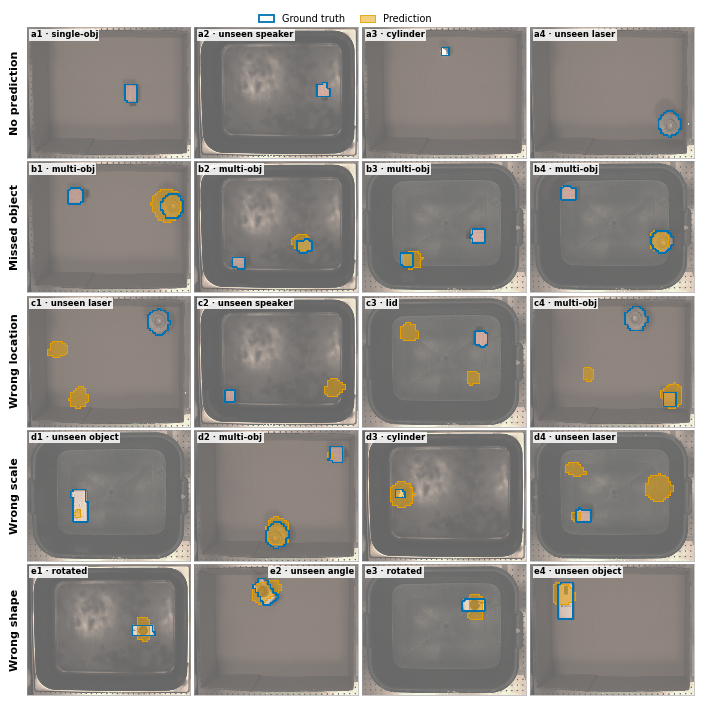

s9-t2-ref-vase-1k@1000 · panel -> sample (row-major; mask p > 0.08, classes on b = p > 0.08)
a1	2026_10_11_cardboard_four_objs/003191-7	pos 3191	spk 7	ID id/cube	1 obj	IoU s9-t2-ref-vase-1k@1000 0.00
a2	2026_09_27_gastronorm_four_objs/000083	pos 17	spk 4	OOD unseen-speaker/cube-unseen-speaker-unseen	1 obj	IoU s9-t2-ref-vase-1k@1000 0.00
a3	2026_10_11_cardboard_four_objs/004341-5	pos 4341	spk 5	OOD cylinder/cylinder-500g	1 obj	IoU s9-t2-ref-vase-1k@1000 0.00
a4	2026_10_11_cardboard_four_objs/004737-1	pos 4737	spk 1	OOD unseen-laser/vase-laser-shifted-3	1 obj	IoU s9-t2-ref-vase-1k@1000 0.00
b1	2026_10_11_cardboard_four_objs/004078-7	pos 4078	spk 7	ID multiple/cube-vase	2 obj	IoU s9-t2-ref-vase-1k@1000 0.39
b2	2026_09_27_gastronorm_four_objs/005661	pos 1133	spk 3	ID multiple/two-cubes	2 obj	IoU s9-t2-ref-vase-1k@1000 0.32
b3	2026_10_05_green_plastic_four_objs/002751-1	pos 2751	spk 1	ID multiple/two-cubes	2 obj	IoU s9-t2-ref-vase-1k@1000 0.26
b4	2026_10_05_green_plastic_four_objs/002780-5	

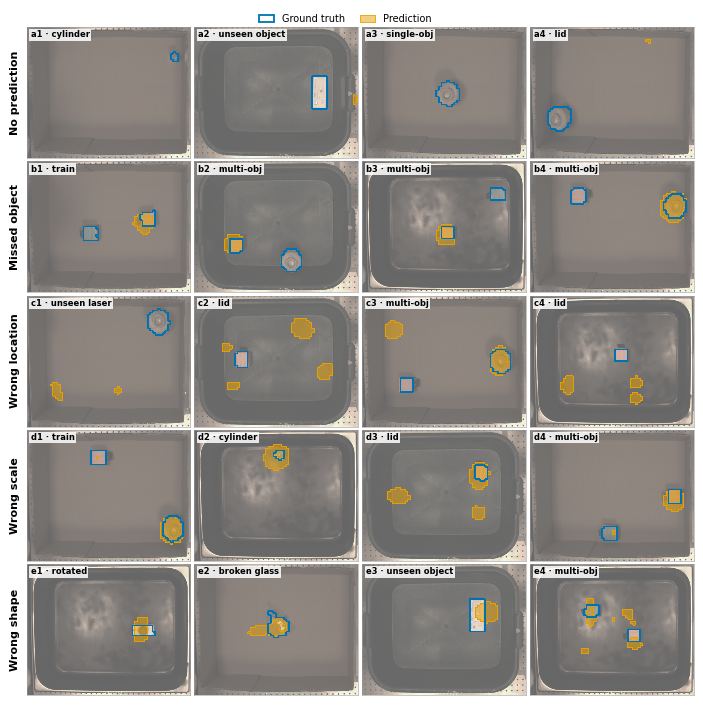

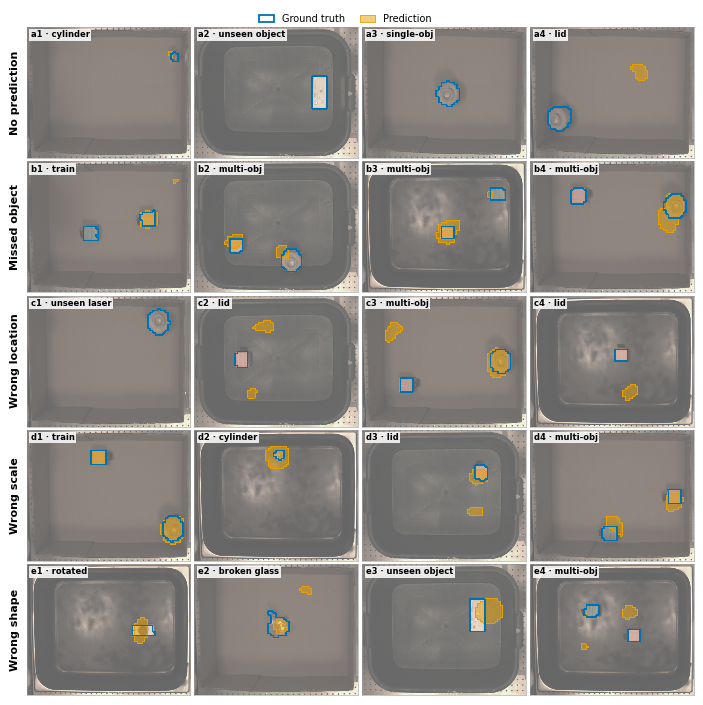

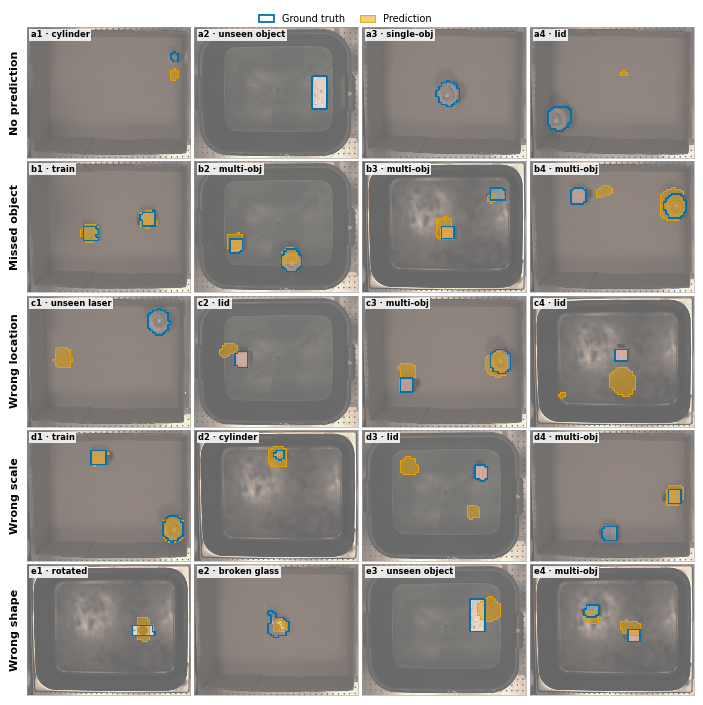

shared samples = decres-rescale-v1@300's worst offenders, drawn for every run · panel -> sample (row-major)
a1	2026_10_11_cardboard_four_objs/004321-5	pos 4321	spk 5	OOD cylinder/cylinder-500g	1 obj	IoU decres-rescale@300 0.00	IoU t4-nowmask@300 0.13	IoU t2-ref@1000 0.00
a2	2026_10_05_green_plastic_four_objs/002873-7	pos 2873	spk 7	OOD unseen-object/portable-charger	1 obj	IoU decres-rescale@300 0.00	IoU t4-nowmask@300 0.00	IoU t2-ref@1000 0.00
a3	2026_10_11_cardboard_four_objs/004715-3	pos 4715	spk 3	other control/vase-without-lid	1 obj	IoU decres-rescale@300 0.00	IoU t4-nowmask@300 0.00	IoU t2-ref@1000 0.00
a4	2026_10_11_cardboard_four_objs/004725-3	pos 4725	spk 3	OOD lid/vase-with-lid	1 obj	IoU decres-rescale@300 0.00	IoU t4-nowmask@300 0.00	IoU t2-ref@1000 0.00
b1	2026_10_11_cardboard_four_objs/004275-7	pos 4275	spk 7	train train/train	2 obj	IoU decres-rescale@300 0.28	IoU t4-nowmask@300 0.40	IoU t2-ref@1000 0.77
b2	2026_10_05_green_plastic_four_objs/002795-5	pos 2795	spk 5	ID multi

,position_id,speaker,box,split,decres-rescale@300,t4-nowmask@300,t2-ref@1000
panel,,,,,,,
a1,4321,5,cardboard,cylinder-500g,No prediction,Wrong scale,Wrong location
a2,2873,7,plastic,portable-charger,No prediction,No prediction,No prediction
a3,4715,3,cardboard,vase-without-lid,No prediction,No prediction,No prediction
a4,4725,3,cardboard,vase-with-lid,No prediction,Wrong location (mirrored),No prediction
b1,4275,7,cardboard,train,Missed object,Missed object,OK
b2,2795,5,plastic,cube-vase,Missed object,Wrong location,Wrong scale
b3,1123,1,gastro,two-cubes,Missed object,Wrong scale,Wrong scale
b4,4078,3,cardboard,cube-vase,Missed object,Missed object,Wrong location
c1,4735,7,cardboard,vase-laser-shifted-3,Wrong location (mirrored),No prediction,Wrong location (mirrored)


In [25]:
# one figure per run, each from its own classes (each run's own worst offenders), + the shared figure: decres-rescale-v1's picks drawn for all three runs
GRID_RUNS = [("decres-rescale-v1", 300, "decres-rescale-v1"), ("t4-nowmask-v1-reeval", 0, "t4-nowmask-v1"), ("s9-t2-ref-vase-1k-reeval", 0, "s9-t2-ref-vase-1k")]
PLOTS = ROOT / "notebooks/plots"
for f in PLOTS.glob("nb132_error_grid_*_caption.txt"): f.unlink()   # superseded by _ids.txt
PICKS = {}
for run, ep, name in GRID_RUNS:
    lab = SHOWN[(run, ep)]
    fig, PICKS[lab] = error_grid(run, ep, DS[lab], DO[lab], n=4, out=PLOTS / f"nb132_error_grid_{name}")
    plt.show()
    ids = f"{lab} · panel -> sample (row-major; mask p > {THR}, classes on b = p > {THR})\n" + grid_ids(PICKS[lab], {lab: "iou08_here"})
    (PLOTS / f"nb132_error_grid_{name}_ids.txt").write_text(ids + "\n"); print(ids, "\n")

shared = PICKS[NEW][["experiment", "sample_id", "position_id", "speaker", "box", "split", "category", "n_obj", "row", "col"]]
for run, ep, name in GRID_RUNS:
    lab = SHOWN[(run, ep)]
    fig, p = error_grid(run, ep, None, None, picks=shared, out=PLOTS / f"nb132_error_grid_shared_{name}")
    plt.show()
    shared = shared.assign(**{f"iou {short(lab)}": p.iou08_here.to_numpy()})
ids = f"shared samples = {NEW}'s worst offenders, drawn for every run · panel -> sample (row-major)\n" + grid_ids(shared, {short(l): f"iou {short(l)}" for l in LABELS})
(PLOTS / "nb132_error_grid_shared_ids.txt").write_text(ids + "\n"); print(ids)

# primary class of the shared samples under each run (is the error model-specific?)
pk = shared[K + ["row", "col"]].assign(panel=lambda d: [f"{'abcde'[r]}{c + 1}" for r, c in zip(d.row, d.col)])
for r in RUNS:
    s = DS[r].drop_duplicates(K); pk = pk.merge(s[K].assign(**{short(r): np.array(NAMES)[primary(s)]}), on=K, how="left")
display(pk.drop(columns=["row", "col", "sample_id", "experiment"]).set_index("panel"))